# EDA логов Hadoop, OpenStack, Android и HPC

@RoMaIlIka · задача №3 · checkpoint 2 · срок 07.11.2026

Посмотрел четыре набора логов из LogHub. Хотел понять, что из них можно использовать для поиска аномалий, где есть разметка и что придётся учесть при подготовке данных. Для каждого набора прохожу те же пункты из чек-листа, чтобы результаты можно было сравнить.

За основу структуры взял `eda_loghub.ipynb`. Загрузка и разбор этих четырёх наборов вынесены в `util.loghub_romailika`.

## Как запустить

Нужен Python 3.11.8 или новее. В корне проекта выполни `python -m pip install -r requirements-eda-romailika.txt`, затем открой ноутбук в этом окружении. При первом запуске `load_loghub` скачает с Zenodo четыре архива (около 37 МБ), проверит их MD5 и распакует в `data/romailika/raw/`. Дальше можно работать с локальными файлами.

Статистику считаю по полным архивам. Для слов, пар слов и упоминаний компонентов беру до 100 000 событий на датасет с `SEED=42`. Отдельно вывожу первые 100 исходных строк и ещё 100 случайных, чтобы глазами проверить, как выглядят логи.

Таблицы, графики и сводки сохраняются в `data/romailika/reports/<dataset>/`. Там же есть ссылки на источники, параметры анализа и SHA-256 исходных файлов.

In [1]:
import gc
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "util" / "loghub_romailika.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Запустите ноутбук из корня проекта или notebooks/")
sys.path.insert(0, str(PROJECT_ROOT))
from util.loghub_romailika import DATASETS, load_loghub
from util.eda_romailika import analyze, show_table, show_raw, plot_overview, plot_dynamics

SEED = 42
DATA_DIR = PROJECT_ROOT / "data" / "romailika" / "raw"
REPORT_DIR = PROJECT_ROOT / "data" / "romailika" / "reports"
SUMMARIES = []
pd.set_option("display.max_columns", 15)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .2})
display(pd.DataFrame(DATASETS).T)

,md5,domain,labels,time
Hadoop,6dfc442b9e86adb519db9437d4e7d3d4,"WordCount/PageRank; 5 machines, injected failures",application/job; not individual lines,"local time, milliseconds; timezone unspecified"
OpenStack,66bd42c07837a094d9b0ea2d036b5713,"CloudLab, OpenStack Nova; failure injection",4 VM instance IDs; file name is capture contex...,"local time, milliseconds; timezone unspecified"
Android,1a1bac1cf0ea95bc88e296f689f0258f,Android_v1; instrumented smartphone applicatio...,unavailable,"month-day, milliseconds; year and timezone una..."
HPC,4a7f0483f7b4fdd8b278c266039db464,LANL System 20 high-performance computing cluster,unavailable; numeric field is not an anomaly l...,"Unix seconds, UTC"


## Hadoop

### 1. Откуда данные

Это логи WordCount и PageRank с кластера из пяти машин (46 ядер). В части запусков специально выключали машину, разрывали сеть или заполняли диск. В `abnormal_label.txt` указан сценарий для задания целиком. Поэтому для каждой записи сохраняю номер задания, тип нагрузки и файл контейнера.

Если исключение занимает несколько строк, собираю его в одно событие в пределах файла. Номера исходных строк остаются в таблице, так что запись можно найти в оригинале.

[Описание Hadoop в LogHub](https://github.com/logpai/loghub/tree/master/Hadoop) · [Архив на Zenodo](https://zenodo.org/records/3227177)

In [2]:
NAME = 'Hadoop'
bundle = load_loghub(NAME, DATA_DIR, seed=SEED)
df = bundle.events
OUT = REPORT_DIR / NAME
result = analyze(bundle, OUT, seed=SEED)
t = result["tables"]
SUMMARIES.append(result["summary"])
display(pd.Series(bundle.manifest))
show_table(pd.DataFrame([result["summary"]]))

dataset                                                           Hadoop
archive_md5                             6dfc442b9e86adb519db9437d4e7d3d4
archive_url            https://zenodo.org/api/records/3227177/files/H...
source_url             https://github.com/logpai/loghub/tree/master/H...
scope                                full archive; no sampling of events
seed                                                                  42
timestamp_semantics       local time, milliseconds; timezone unspecified
dtype: object

,dataset,duplicate_physical_lines,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,continuation_lines,logical_events,timestamp_missing,start,end,unique_templates,top10_template_share_pct,mean_message_length,singleton_messages,files,sample_text_events,backwards_steps,duplicate_timestamps_within_files
0,Hadoop,214689,394310,47809614,213414,877,0,391673,2,213414,180896,0,2015-10-17 15:37:56.547000,2015-10-19 18:08:58.030000,4586,58.36,165.814,51838,978,100000,13,62068


### 2–3. Файлы и первые строки

Сначала проверяю, что лежит в архиве. В `files` есть размеры, SHA-256, типы перевода строки (LF/CRLF), число пустых строк и строки без завершающего переноса. Читаю файлы как UTF-8 и отмечаю строки с символом замены `�`.

Точные повторы текста считаю по хэшу BLAKE2b и оставляю в данных. В Hadoop у одной записи может быть несколько строк, поэтому `raw_length` включает и переносы внутри неё. Ниже можно посмотреть обычные строки, стеки ошибок и то, что не удалось разобрать.

In [3]:
show_table(t["files"], 12)
show_table(t["quality"], 30)
show_table(t["lengths"])
show_table(t["text_summary"], 20)
show_table(t["unparsed"])
show_raw(t["first_100"], "Первые 100 физических строк (в порядке файлов и строк)")
show_raw(t["random_100"], "100 физических строк: reservoir sampling по всему корпусу, seed=42")

,source_file,bytes,sha256,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,continuation_lines
0,application_1445062781478_0011/container_1445062781478_0011_01_000001.log,239767,206e55fa11e9b0a5a7b8e521194ab7ee8db6476819c19064803c43560e4aa036,1282,237249,72,12,0,1236,0,72.0
1,application_1445062781478_0011/container_1445062781478_0011_01_000002.log,8417,3bc7a0b0102906d4ae93d1c41c31e1a76aa6361509acdcd22ec5dcb1b0a2480a,68,8281,0,0,0,68,0,NaN
2,application_1445062781478_0011/container_1445062781478_0011_01_000003.log,8423,99bdca517aca1a2961f056f626b8c0bfeafe63dcea0bced7bb2ce4e0c4330438,68,8287,0,0,0,68,0,NaN
3,application_1445062781478_0011/container_1445062781478_0011_01_000004.log,8424,70a129b1ed50c74b7aeea179c2dca352f4bf45bdd4a05a47e99bb396b7fa7f15,68,8288,0,0,0,68,0,NaN
4,application_1445062781478_0011/container_1445062781478_0011_01_000005.log,8424,3663a2422bc80211477018bf370497dec64a7a6a6580516bdebac1ebd61e294b,68,8288,0,0,0,68,0,NaN
5,application_1445062781478_0011/container_1445062781478_0011_01_000006.log,8424,55b30ccb33580c63b45d7c5a18a84df639f00d488299e554361090e7374e189f,68,8288,0,0,0,68,0,NaN
6,application_1445062781478_0011/container_1445062781478_0011_01_000007.log,8424,e415861b918a769cc644fe6750262528dd3c7e6677e22ca04add01d0d48493d7,68,8288,0,0,0,68,0,NaN
7,application_1445062781478_0011/container_1445062781478_0011_01_000008.log,8423,b3b062dca9cc29db542dc487dac94fd3e64bb2e4ed754201f8a85b52f7392eb1,68,8287,0,0,0,68,0,NaN
8,application_1445062781478_0011/container_1445062781478_0011_01_000009.log,8423,06d27e38a7726540b37ddc6a77c0a5257570c84edfdcc5b906b891ebdcad68b2,68,8287,0,0,0,68,0,NaN
9,application_1445062781478_0011/container_1445062781478_0011_01_000010.log,8424,fa797d998e06f29c2a44cb57baa782db531b926708251e59750b6b65eb790111,68,8288,0,0,0,68,0,NaN


,value
metric,
duplicate_physical_lines,214689
physical_lines,394310
physical_characters,47809614
lines_without_standard_header,213414
blank_lines,877
invalid_utf8_lines,0
crlf_lines,391673
missing_final_newline,2
continuation_lines,213414


,count,mean,std,min,50%,90%,99%,max
raw_length,180896.0,265.473134,483.644309,65.0,187.0,223.0,2887.0,8907.0
message_length,180896.0,165.813567,481.863316,12.0,77.0,130.0,2783.0,8824.0
physical_lines,180896.0,2.179761,6.262994,1.0,1.0,1.0,36.0,178.0


,value
metric,
unique_messages,6.175500e+04
singleton_messages,5.183800e+04
duplicate_logical_messages,1.191410e+05
mean_physical_line_chars,1.212490e+02
digits_chars,4.770804e+06
digits_share_pct,1.590500e+01
letters_chars,2.020613e+07
letters_share_pct,6.736500e+01
punctuation_chars,2.573698e+06


,source_file,line_start,message


### 4. Время

По каждому файлу смотрю начало и конец записи, совпадающие отметки времени, скачки назад и паузы между событиями. В таблице есть медианная положительная пауза и самая длинная. Файлы проверяю отдельно, потому что это могут быть разные запуски. По паузе в логах трудно понять, остановилась система или прервался сбор.

Если часовой пояс в данных неизвестен, оставляю время как есть. Строки без читаемой даты по-прежнему входят в анализ текста.

In [4]:
show_table(t["time_by_file"], 12)
show_table(t["largest_gaps"], 12)
show_table(df.loc[df.timestamp.isna(), ["source_file", "line_start", "time", "message"]], 10)

,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
0,application_1445062781478_0011/container_1445062781478_0011_01_000001.log,2015-10-17 15:37:56.547,2015-10-17 15:42:47.708,1,260,15.037,0.0300
1,application_1445062781478_0011/container_1445062781478_0011_01_000002.log,2015-10-17 15:38:04.118,2015-10-17 15:40:34.100,0,27,28.300,0.2020
2,application_1445062781478_0011/container_1445062781478_0011_01_000003.log,2015-10-17 15:38:05.115,2015-10-17 15:40:50.073,0,27,36.317,0.4040
3,application_1445062781478_0011/container_1445062781478_0011_01_000004.log,2015-10-17 15:38:05.150,2015-10-17 15:40:50.246,0,26,36.122,0.3540
4,application_1445062781478_0011/container_1445062781478_0011_01_000005.log,2015-10-17 15:38:04.075,2015-10-17 15:40:32.067,0,27,27.553,0.2055
5,application_1445062781478_0011/container_1445062781478_0011_01_000006.log,2015-10-17 15:38:05.163,2015-10-17 15:40:50.547,0,24,36.210,0.3600
6,application_1445062781478_0011/container_1445062781478_0011_01_000007.log,2015-10-17 15:38:04.081,2015-10-17 15:40:28.620,0,25,27.564,0.1370
7,application_1445062781478_0011/container_1445062781478_0011_01_000008.log,2015-10-17 15:38:05.400,2015-10-17 15:41:25.758,0,32,25.177,1.0160
8,application_1445062781478_0011/container_1445062781478_0011_01_000009.log,2015-10-17 15:38:05.337,2015-10-17 15:41:12.363,0,34,30.630,2.7810
9,application_1445062781478_0011/container_1445062781478_0011_01_000010.log,2015-10-17 15:38:05.431,2015-10-17 15:40:52.280,0,34,29.579,2.4850


,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
508,application_1445094324383_0003/container_1445094324383_0003_01_000013.log,2015-10-17 23:10:07.310,2015-10-17 23:27:58.237,0,41,787.210,0.1250
429,application_1445087491445_0009/container_1445087491445_0009_01_000001.log,2015-10-17 22:26:37.008,2015-10-17 22:57:05.136,0,530,609.737,0.3430
765,application_1445182159119_0002/container_1445182159119_0002_02_000002.log,2015-10-19 14:32:30.261,2015-10-19 14:41:54.885,0,29,524.923,0.0315
530,application_1445094324383_0004/container_1445094324383_0004_01_000016.log,2015-10-17 23:13:08.846,2015-10-17 23:35:28.420,0,25,508.085,0.1250
782,application_1445182159119_0003/container_1445182159119_0003_01_000017.log,2015-10-19 14:26:48.930,2015-10-19 14:42:54.569,0,41,469.716,0.0940
743,application_1445182159119_0001/container_1445182159119_0001_01_000012.log,2015-10-19 14:23:06.173,2015-10-19 14:31:37.329,0,16,457.147,0.0245
270,application_1445087491445_0001/container_1445087491445_0001_01_000016.log,2015-10-17 21:25:55.739,2015-10-17 21:45:51.046,0,19,455.148,0.0120
481,application_1445094324383_0001/container_1445094324383_0001_01_000012.log,2015-10-17 23:11:21.739,2015-10-17 23:20:31.051,0,11,443.236,0.0220
799,application_1445182159119_0004/container_1445182159119_0004_01_000018.log,2015-10-19 14:27:35.765,2015-10-19 14:41:35.156,0,44,414.713,0.0310
379,application_1445087491445_0005/container_1445087491445_0005_01_000022.log,2015-10-17 21:51:18.803,2015-10-17 22:01:25.498,0,57,401.486,0.0310


,source_file,line_start,time,message


### 5. Объём и распределения

Смотрю, какие уровни и компоненты встречаются чаще и как меняется поток событий по файлам. Дневные доли компонентов считаю среди восьми самых частых, чтобы сравнение было проще читать. Для Hadoop надёжного поля с хостом в этих данных нет. Число событий за минуту, час и день есть в разделе про окна.

**level**

,count,share_pct
level,,
INFO,168920,93.380
WARN,11438,6.323
ERROR,521,0.288
FATAL,17,0.009


**component**

,count,share_pct
component,,
org.apache.hadoop.mapred.TaskAttemptListenerImpl,66558,36.794
org.apache.hadoop.mapred.MapTask,36991,20.449
org.apache.hadoop.mapreduce.v2.app.rm.RMContainerAllocator,14711,8.132
org.apache.hadoop.ipc.Client,9360,5.174
org.apache.hadoop.mapreduce.v2.app.job.impl.TaskAttemptImpl,7063,3.904
org.apache.hadoop.hdfs.LeaseRenewer,5300,2.930
org.apache.hadoop.mapreduce.v2.app.launcher.ContainerLauncherImpl,4488,2.481
org.apache.hadoop.mapred.YarnChild,3641,2.013
org.apache.hadoop.mapreduce.v2.app.job.impl.TaskImpl,3341,1.847


**thread**

,count,share_pct
thread,,
main,49606,27.422
RMCommunicator Allocator,16302,9.012
AsyncDispatcher event handler,15375,8.499
LeaseRenewer:msrabi@msra-sa-41:9000,10601,5.860
SpillThread,4580,2.532
fetcher#5,1695,0.937
communication thread,1330,0.735
fetcher#1,943,0.521
ContainerLauncher #1,906,0.501


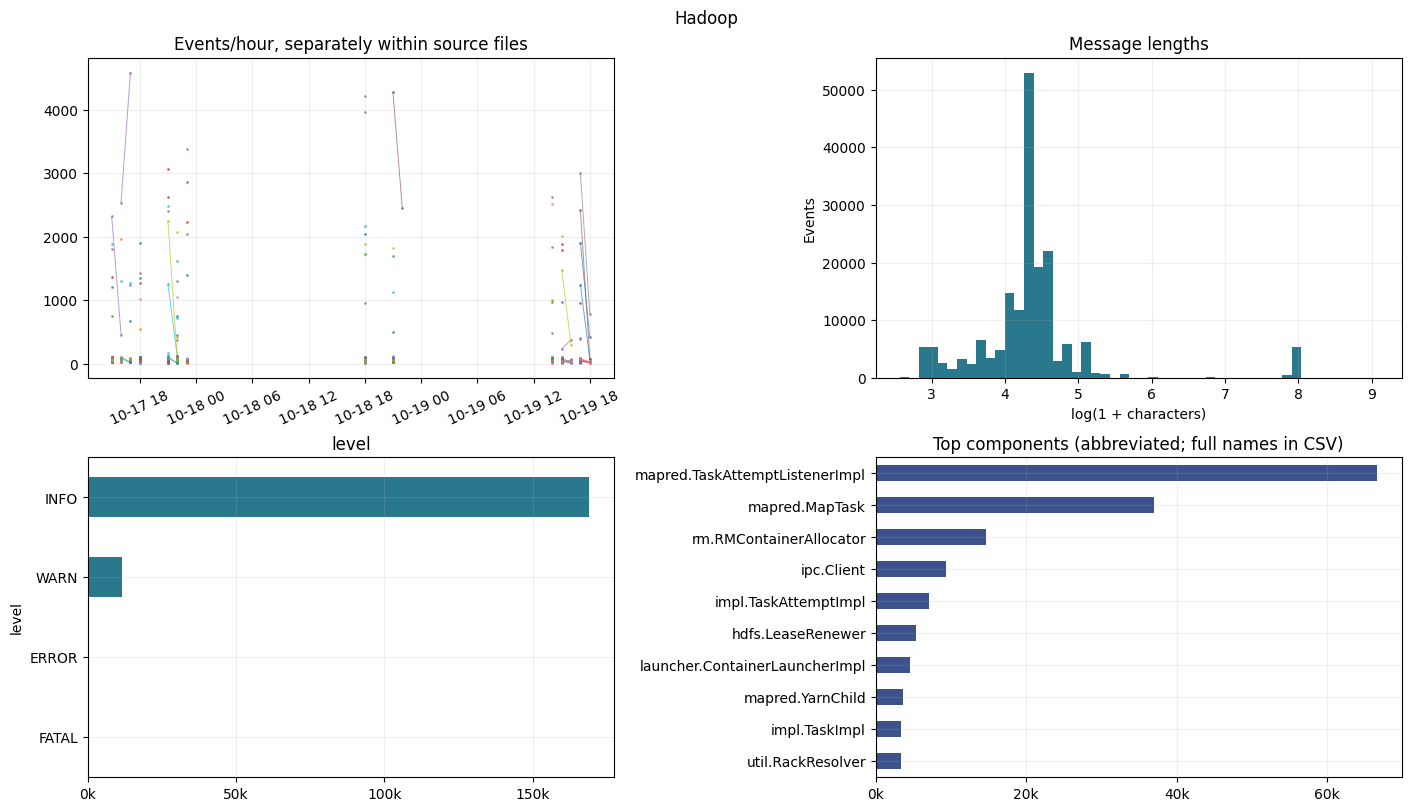

**level_daily_share**

level,ERROR,FATAL,INFO,WARN
timestamp,,,,
2015-10-17,0.0002,0.0000,0.9975,0.0022
2015-10-18,0.0125,0.0001,0.7041,0.2833
2015-10-19,0.0002,0.0003,0.9979,0.0016


**component_daily_share**

component,org.apache.hadoop.hdfs.LeaseRenewer,org.apache.hadoop.ipc.Client,org.apache.hadoop.mapred.MapTask,org.apache.hadoop.mapred.TaskAttemptListenerImpl,org.apache.hadoop.mapred.YarnChild,org.apache.hadoop.mapreduce.v2.app.job.impl.TaskAttemptImpl,org.apache.hadoop.mapreduce.v2.app.launcher.ContainerLauncherImpl,org.apache.hadoop.mapreduce.v2.app.rm.RMContainerAllocator
timestamp,,,,,,,,
2015-10-17,0.0004,0.0285,0.2627,0.5155,0.0263,0.0517,0.0329,0.0820
2015-10-18,0.1569,0.2041,0.2027,0.2539,0.0195,0.0352,0.0225,0.1051
2015-10-19,0.0000,0.0073,0.2653,0.4872,0.0255,0.0506,0.0319,0.1322


In [5]:
for column in ["level", "component", "host", "resource", "event_type", "pid", "thread", "capture", "format_variant"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column])
plot_overview(bundle, OUT)
for column in ["level_daily_share", "component_daily_share", "host_daily_share"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 12)

### 6. Что пишут в логах

На всех событиях сравниваю длины сообщений, частые и единичные строки. При подсчёте долей букв, цифр и знаков препинания учитываю каждое вхождение сообщения.

Для слов и пар слов беру случайную выборку. Учитываю латиницу от трёх символов, привожу к нижнему регистру и показываю 15 самых частых и 15 редких вариантов. Имена других компонентов ищу по точному совпадению. Так можно увидеть, кто кого упоминает в логах.

In [6]:
for table in ["common_messages", "rare_messages", "longest_messages", "words_sample", "bigrams_sample", "component_mentions_sample"]:
    display(Markdown("**" + table + "**"))
    show_table(t[table], 30)

**common_messages**

,message,count
0,Spilling map output,5339
1,Address change detected. Old: msra-sa-41/10.190.173.170:9000 New: msra-sa-41:9000,5313
2,Reduce slow start threshold not met. completedMapsForReduceSlowstart 1,3841
3,MapCompletionEvents request from attempt_1445062781478_0017_r_000000_0. startIndex 7 maxEvents 10000,3312
4,"Recalculating schedule, headroom=<memory:0, vCores:-27>",2297
5,Resolved MSRA-SA-41.fareast.corp.microsoft.com to /default-rack,1377
6,MapCompletionEvents request from attempt_1445182159119_0016_r_000000_0. startIndex 9 maxEvents 10000,1167
7,Progress of TaskAttempt attempt_1445062781478_0017_r_000000_0 is : 0.23333333,1086
8,Resolved MSRA-SA-39.fareast.corp.microsoft.com to /default-rack,1072
9,"Recalculating schedule, headroom=<memory:0, vCores:-35>",1003


**rare_messages**

,message,count
0,for url=13562/mapOutput?job=job_1445062781478_0014&reduce=0&map=attempt_1445062781478_0014_m_000006_0 sent hash and received reply,1
1,attempt_1445062781478_0014_m_000006_0: Shuffling to disk since 60515100 is greater than maxSingleShuffleLimit (35232152),1
2,fetcher#5 about to shuffle output of map attempt_1445062781478_0014_m_000006_0 decomp: 60515100 len: 60515104 to DISK,1
3,Read 60515104 bytes from map-output for attempt_1445062781478_0014_m_000006_0,1
4,MSRA-SA-39.fareast.corp.microsoft.com:13562 freed by fetcher#5 in 1474ms,1
5,for url=13562/mapOutput?job=job_1445062781478_0014&reduce=0&map=attempt_1445062781478_0014_m_000007_0 sent hash and received reply,1
6,attempt_1445062781478_0014_m_000007_0: Shuffling to disk since 60517368 is greater than maxSingleShuffleLimit (35232152),1
7,fetcher#5 about to shuffle output of map attempt_1445062781478_0014_m_000007_0 decomp: 60517368 len: 60517372 to DISK,1
8,for url=13562/mapOutput?job=job_1445062781478_0014&reduce=0&map=attempt_1445062781478_0014_m_000002_0 sent hash and received reply,1
9,attempt_1445062781478_0014_m_000002_0: Shuffling to disk since 60514392 is greater than maxSingleShuffleLimit (35232152),1


**longest_messages**

,source_file,line_start,message_length,message
134009,application_1445175094696_0004/container_1445175094696_0004_01_000004.log,455,8824,Process Thread Dump: Communication exception\n15 active threads\nThread 55 (Readahead Thread #3):\n State: WAITING\n Blocked count: 0\n Waited count: 24\n Waiting on java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject@632e7cf3\n Stack:\n sun.misc.Unsafe.park(Native Method)\n java.util.concurrent.locks.LockSupport.park(LockSupport.java:186)\n java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject.await(AbstractQueuedSynchronizer.java:2043)\n java.util.concur…
109333,application_1445144423722_0022/container_1445144423722_0022_01_000006.log,147,6294,Process Thread Dump: Communication exception\n12 active threads\nThread 21 (SpillThread):\n State: WAITING\n Blocked count: 0\n Waited count: 6\n Waiting on java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject@2e498b1\n Stack:\n sun.misc.Unsafe.park(Native Method)\n java.util.concurrent.locks.LockSupport.park(LockSupport.java:186)\n java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject.await(AbstractQueuedSynchronizer.java:2043)\n org.apache.hadoop.mapred.M…
109456,application_1445144423722_0022/container_1445144423722_0022_01_000008.log,141,6294,Process Thread Dump: Communication exception\n12 active threads\nThread 21 (SpillThread):\n State: WAITING\n Blocked count: 0\n Waited count: 5\n Waiting on java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject@3542d6bb\n Stack:\n sun.misc.Unsafe.park(Native Method)\n java.util.concurrent.locks.LockSupport.park(LockSupport.java:186)\n java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject.await(AbstractQueuedSynchronizer.java:2043)\n org.apache.hadoop.mapred.…
134250,application_1445175094696_0004/container_1445175094696_0004_01_000008.log,129,6294,Process Thread Dump: Communication exception\n12 active threads\nThread 21 (SpillThread):\n State: WAITING\n Blocked count: 0\n Waited count: 3\n Waiting on java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject@4166d6d3\n Stack:\n sun.misc.Unsafe.park(Native Method)\n java.util.concurrent.locks.LockSupport.park(LockSupport.java:186)\n java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject.await(AbstractQueuedSynchronizer.java:2043)\n org.apache.hadoop.mapred.…
134196,application_1445175094696_0004/container_1445175094696_0004_01_000007.log,135,6293,Process Thread Dump: Communication exception\n12 active threads\nThread 21 (SpillThread):\n State: WAITING\n Blocked count: 0\n Waited count: 4\n Waiting on java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject@220336f0\n Stack:\n sun.misc.Unsafe.park(Native Method)\n java.util.concurrent.locks.LockSupport.park(LockSupport.java:186)\n java.util.concurrent.locks.AbstractQueuedSynchronizer$ConditionObject.await(AbstractQueuedSynchronizer.java:2043)\n org.apache.hadoop.mapred.…


... (2 outputs left out)

**bigrams_sample**

,token,count
0,org apache,71353
1,apache hadoop,71344
2,java org,61919
3,taskattempt attempt_,27051
4,hadoop ipc,26662
5,progress taskattempt,25497
6,ipc client,22745
7,client java,22745
8,hadoop hdfs,17768
9,hadoop net,15885


**component_mentions_sample**

,source_component,mentioned_component,messages
0,org.apache.hadoop.hdfs.LeaseRenewer,org.apache.hadoop.ipc.Client,2911
1,org.apache.hadoop.yarn.event.AsyncDispatcher,org.apache.hadoop.mapreduce.v2.app.MRAppMaster,273
2,org.apache.hadoop.mapreduce.v2.app.rm.RMContainerAllocator,org.apache.hadoop.ipc.Client,264
3,org.apache.hadoop.mapreduce.v2.app.MRAppMaster,org.apache.hadoop.mapreduce.lib.output.FileOutputCommitter,39
4,org.apache.hadoop.yarn.event.AsyncDispatcher,org.apache.hadoop.mapreduce.v2.app.commit.CommitterEventHandler,34
5,org.apache.hadoop.mapred.Task,org.apache.hadoop.ipc.Client,31
6,org.apache.hadoop.yarn.event.AsyncDispatcher,org.apache.hadoop.mapreduce.jobhistory.JobHistoryEventHandler,28
7,org.apache.hadoop.hdfs.DFSClient,org.apache.hadoop.mapred.YarnChild,10
8,org.apache.hadoop.mapred.TaskAttemptListenerImpl,org.apache.hadoop.mapred.MapTask,9
9,org.apache.hadoop.hdfs.DFSClient,org.apache.hadoop.mapred.MapTask,9


### 7. Адреса и идентификаторы

Считаю, сколько в тексте адресов, UUID, URL, путей, номеров портов и других идентификаторов и сколько из них уникальны. IPv4 проверяю на валидность. Порты ищу рядом с адресом или словом `port` и проверяю диапазон.

Совпадения по шаблону требуют проверки. Например, 32 шестнадцатеричных символа могут быть и хэшем, и обычным ID. Поля с ID сессии, запроса или VM смотрю отдельно от упоминаний в тексте. Для Hadoop удобно группировать записи по ID задания.

In [7]:
show_table(t["entities"], 20)
show_table(t["entity_examples"], 80)
for column in ["session_id", "request_id", "instance_id", "numeric_flag"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 15)

,entity,unique,mentions
0,url,50,5389
1,uuid,0,0
2,ipv4,9,15613
3,port,225,9740
4,path,422,5086
5,hash,0,0
6,device,0,0
7,session_candidate,2555,93626


,entity,value,mentions
0,url,http://wiki.apache.org/hadoop/NoRouteToHost,5340
1,url,http://MSRA-SA-41.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445062781478_0015,1
2,url,http://MSRA-SA-41.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445062781478_0018,1
3,url,http://MSRA-SA-41.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445062781478_0019,1
4,url,http://MSRA-SA-41.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445062781478_0020,1
5,url,http://04DN8IQ.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445076437777_0002,1
6,url,http://04DN8IQ.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445076437777_0005,1
7,url,http://MSRA-SA-39.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445087491445_0001,1
8,url,http://wiki.apache.org/hadoop/ConnectionRefused,1
9,url,http://MSRA-SA-41.fareast.corp.microsoft.com:19888/jobhistory/job/job_1445087491445_0002,1


**session_id**

,count,share_pct
session_id,,
application_1445175094696_0003,8304,4.590
application_1445062781478_0017,8098,4.477
application_1445144423722_0020,7930,4.384
application_1445144423722_0023,7075,3.911
application_1445087491445_0004,5446,3.011
application_1445182159119_0016,4657,2.574
application_1445087491445_0002,4613,2.550
application_1445094324383_0005,4582,2.533
application_1445087491445_0003,4388,2.426


### 8. Шаблоны сообщений

Чтобы похожие строки попали в одну группу, заменяю переменные части вроде IP, UUID, путей и чисел общими метками и убираю лишние пробелы. Регулярные выражения дают первую оценку. Иногда они склеивают разные события или разбивают похожие строки на несколько групп.

Смотрю частые и редкие шаблоны и отмечаю, когда они впервые и в последний раз попались в этих логах. Полная таблица с датами есть в CSV.

In [8]:
show_table(t["templates_common"], 20)
show_table(t["templates_rare"], 15)
show_table(t["template_endpoints"], 16)

,template,count
0,Progress of TaskAttempt <session_candidate> is : <num>,45880
1,MapCompletionEvents request from <session_candidate>. startIndex <num> maxEvents <num>,18139
2,Address change detected. Old: msra-sa-<num>/<ipv4>:<num> New: msra-sa-<num>:<num>,5795
3,(EQUATOR) <num> kvi <num>(<num>),5542
4,bufstart = <num>; bufend = <num>; bufvoid = <num>,5339
5,kvstart = <num>(<num>); kvend = <num>(<num>); length = <num>/<num>,5339
6,Spilling map output,5339
7,Finished spill <num>,5204
8,(RESET) equator <num> kv <num>(<num>) kvi <num>(<num>),4579
9,"Recalculating schedule, headroom=<memory:<num>, vCores:<num>>",4415


,template,count
0,JVM with ID : jvm_1445182159119_0020_m_000013 asked for a task,1
1,JVM with ID: jvm_1445182159119_0020_r_000012 given task: <session_candidate>,1
2,JVM with ID : jvm_1445182159119_0020_r_000012 asked for a task,1
3,JVM with ID: jvm_1445182159119_0020_m_000010 given task: <session_candidate>,1
4,JVM with ID : jvm_1445182159119_0020_m_000010 asked for a task,1
5,Extract jar:file:/D:/hadoop-<num>.<num>-localbox/share/hadoop/yarn/hadoop-yarn-common-<num>.<num>-SNAPSHOT.jar!<path> to C:\Users\msrabi\AppData\Local\Temp\<num>\Jetty_0_0_0_0_47462_mapreduce____j3iclo\webapp,1
6,JVM with ID: jvm_1445182159119_0020_m_000011 given task: <session_candidate>,1
7,JVM with ID : jvm_1445182159119_0020_m_000011 asked for a task,1
8,JVM with ID: jvm_1445182159119_0020_m_000009 given task: <session_candidate>,1
9,JVM with ID : jvm_1445182159119_0020_m_000009 asked for a task,1


,template,count,first_seen,last_seen,span_seconds,selection
0,"MapCompletionEvents request from <session_candidate>. startIndex <num> maxEvents <num> <num>-<num>-<num> <num>:<num>:<num>,<num> INFO [IPC Server handler <num> on <num>] org.apache.hadoop.map",1,2015-10-19 18:08:58.030,2015-10-19 18:08:58.030,0.0,latest first appearance
1,Copying hdfs://msra-sa-<num>:<num>/tmp/hadoop-yarn/staging/msrabi/.staging/job_1445182159119_0018/job_1445182159119_0018_2_conf.xml to hdfs://msra-sa-<num>:<num>/tmp/hadoop-yarn/staging <path>,1,2015-10-19 18:03:21.407,2015-10-19 18:03:21.407,0.0,latest first appearance
2,Copying hdfs://msra-sa-<num>:<num>/tmp/hadoop-yarn/staging/msrabi/.staging/job_1445182159119_0018/job_1445182159119_0018_2.jhist to hdfs://msra-sa-<num>:<num>/tmp/hadoop-yarn/staging <path>,1,2015-10-19 18:03:21.251,2015-10-19 18:03:21.251,0.0,latest first appearance
3,job_1445182159119_0018Job Transitioned from COMMITTING to SUCCEEDED,1,2015-10-19 18:03:21.110,2015-10-19 18:03:21.110,0.0,latest first appearance
4,job_1445182159119_0018Job Transitioned from RUNNING to COMMITTING,1,2015-10-19 18:03:21.016,2015-10-19 18:03:21.016,0.0,latest first appearance
5,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 10477ms,1,2015-10-19 18:02:09.413,2015-10-19 18:02:09.413,0.0,latest first appearance
6,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 10162ms,1,2015-10-19 18:01:39.962,2015-10-19 18:01:39.962,0.0,latest first appearance
7,Copying hdfs://msra-sa-<num>:<num>/tmp/hadoop-yarn/staging/msrabi/.staging/job_1445182159119_0019/job_1445182159119_0019_2_conf.xml to hdfs://msra-sa-<num>:<num>/tmp/hadoop-yarn/staging <path>,1,2015-10-19 18:01:18.882,2015-10-19 18:01:18.882,0.0,latest first appearance
8,Created MRAppMaster for application appattempt_1445062781478_0011_000001,1,2015-10-17 15:37:56.547,2015-10-17 15:37:56.547,0.0,earliest last appearance
9,Created MRAppMaster for application appattempt_1445062781478_0012_000001,1,2015-10-17 15:37:57.969,2015-10-17 15:37:57.969,0.0,earliest last appearance


### 9. Разметка и примеры

Сравниваю обычные задания с заданиями, где специально вызвали сбой. Для каждого сценария смотрю, сколько было событий, какой у них уровень, длина и какие встречаются шаблоны. Ниже до десяти примеров из разных заданий. Среди строк одного проблемного задания есть и обычные сообщения.

Для таблицы эпизодов объединяю записи одного задания в одном файле, если между ними прошло не больше минуты. Получившийся интервал показывает, когда в логе шли эти записи. Точное время начала и конца сбоя по нему установить нельзя.

,session_id,workload,context_label
0,application_1445087491445_0005,WordCount,Normal
1,application_1445087491445_0007,WordCount,Normal
2,application_1445175094696_0005,WordCount,Normal
3,application_1445087491445_0001,WordCount,Machine down
4,application_1445087491445_0002,WordCount,Machine down
5,application_1445087491445_0003,WordCount,Machine down
6,application_1445087491445_0004,WordCount,Machine down
7,application_1445087491445_0006,WordCount,Machine down
8,application_1445087491445_0008,WordCount,Machine down
9,application_1445087491445_0009,WordCount,Machine down


**label_units**

,labelled_units,share_pct
context_label,,
Disk full,9,16.364
Machine down,28,50.909
Network disconnection,7,12.727
Normal,11,20.000


**session_summary**

,session_id,context_label,workload,events,physical_lines,first_seen,last_seen
0,application_1445062781478_0011,Normal,PageRank,2045,2121,2015-10-17 15:37:56.547,2015-10-17 15:42:47.708
1,application_1445062781478_0012,Machine down,PageRank,3800,3930,2015-10-17 15:37:57.969,2015-10-17 16:40:13.278
2,application_1445062781478_0013,Machine down,PageRank,3840,4237,2015-10-17 15:37:58.425,2015-10-17 15:58:04.500
3,application_1445062781478_0014,Machine down,PageRank,2809,2901,2015-10-17 15:38:02.829,2015-10-17 15:47:23.547
4,application_1445062781478_0015,Machine down,PageRank,2735,2835,2015-10-17 15:43:47.586,2015-10-17 15:51:00.077
5,application_1445062781478_0016,Normal,PageRank,2121,2196,2015-10-17 16:47:34.992,2015-10-17 16:53:55.214
6,application_1445062781478_0017,Machine down,PageRank,8098,8230,2015-10-17 16:47:38.896,2015-10-17 17:52:32.221
7,application_1445062781478_0018,Machine down,PageRank,3992,4197,2015-10-17 16:47:38.357,2015-10-17 17:15:08.359
8,application_1445062781478_0019,Normal,PageRank,2075,2160,2015-10-17 17:06:25.314,2015-10-17 17:11:08.940
9,application_1445062781478_0020,Machine down,PageRank,2118,2218,2015-10-17 17:15:17.514,2015-10-17 17:20:10.696


**context_label**

... (7 outputs left out)

**failure_context_episodes**

,source_file,session,start,end,seconds,events
90,application_1445062781478_0017/container_1445062781478_0017_01_000001.log,application_1445062781478_0017,2015-10-17 16:47:38.896,2015-10-17 17:52:32.221,3893.325,7121
674,application_1445175094696_0003/container_1445175094696_0003_01_000001.log,application_1445175094696_0003,2015-10-18 21:33:02.241,2015-10-18 22:20:29.316,2847.075,6728
553,application_1445144423722_0020/container_1445144423722_0020_01_000001.log,application_1445144423722_0020,2015-10-18 18:01:47.978,2015-10-18 18:28:43.782,1615.804,4216
606,application_1445144423722_0023/container_1445144423722_0023_01_000001.log,application_1445144423722_0023,2015-10-18 18:01:51.853,2015-10-18 18:28:43.282,1611.429,3956
895,application_1445182159119_0016/container_1445182159119_0016_01_000001.log,application_1445182159119_0016,2015-10-19 17:39:14.520,2015-10-19 18:08:58.030,1783.510,3782
518,application_1445094324383_0005/container_1445094324383_0005_01_000001.log,application_1445094324383_0005,2015-10-17 23:07:57.034,2015-10-17 23:50:02.006,2524.972,3387
277,application_1445087491445_0003/container_1445087491445_0003_01_000001.log,application_1445087491445_0003,2015-10-17 21:24:11.456,2015-10-17 21:47:37.380,1405.924,3059
491,application_1445094324383_0004/container_1445094324383_0004_01_000001.log,application_1445094324383_0004,2015-10-17 23:07:58.868,2015-10-17 23:35:34.842,1655.974,2859
0,application_1445062781478_0012/container_1445062781478_0012_01_000001.log,application_1445062781478_0012,2015-10-17 15:37:57.969,2015-10-17 16:40:13.278,3735.309,2772
773,application_1445182159119_0004/container_1445182159119_0004_01_000001.log,application_1445182159119_0004,2015-10-19 14:21:37.362,2015-10-19 14:41:37.578,1200.216,2632


**templates_context_exclusive**

,context,template,count
0,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 10162ms,1
1,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 10477ms,1
2,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 10708ms,1
3,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 108850ms,1
4,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 11028ms,1
5,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 12227ms,1
6,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 136300ms,1
7,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 13721ms,1
8,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 14173ms,1
9,failure context only,04DN8IQ.fareast.corp.microsoft.com:<num> freed by fetcher#<num> in 14806ms,1


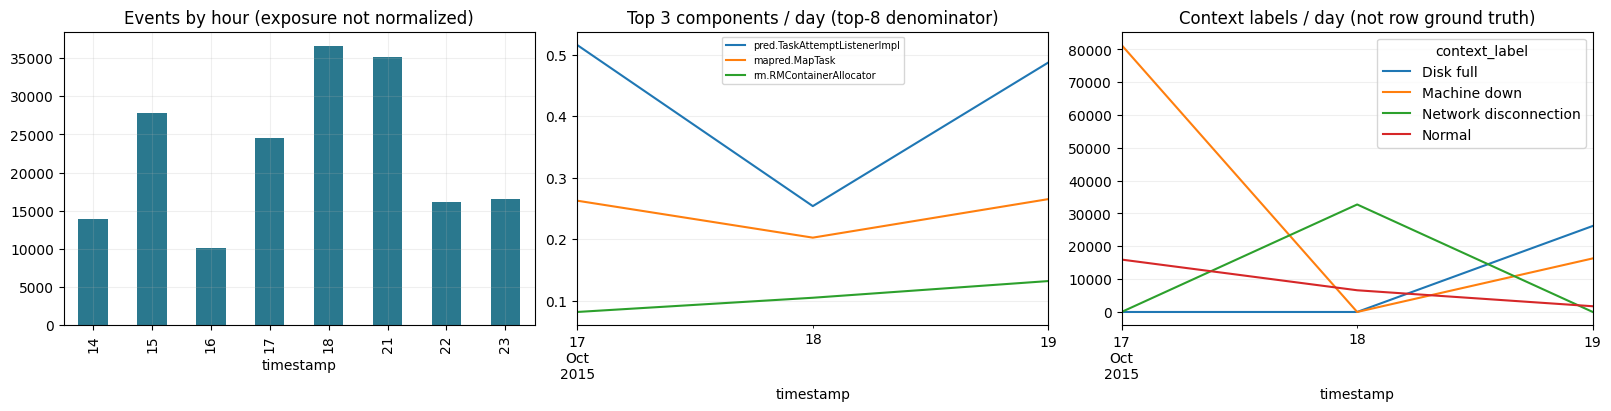

In [9]:
if bundle.labels.empty:
    display(Markdown("В архиве нет подтверждённых меток аномалий; качество детектора по этим данным оценить нельзя."))
else:
    show_table(t["labels_source"], 60)
    for table in ["label_units", "session_summary", "context_label", "label_comparison", "level_by_label", "anomaly_examples", "failure_context_episodes", "templates_context_exclusive"]:
        if table in t:
            display(Markdown("**" + table + "**"))
            show_table(t[table], 15)
plot_dynamics(bundle, result, OUT)

### 10. Временные окна

Пробую четыре размера окна — минута, пять минут, час и сутки. Окна считаю отдельно по каждому файлу от первой до последней записи. Пустые окна внутри файла тоже попадают в статистику и квантили, а паузы между файлами не учитываются. В коротком логе контейнера крайнее окно может быть неполным.

In [10]:
show_table(t["windows"])
assert int(df.physical_lines.sum()) == bundle.quality["physical_lines"]
assert int(df.parse_ok.sum()) + int((~df.parse_ok).sum()) == len(df)
assert len(bundle.raw_first) == min(100, bundle.quality["physical_lines"])
assert len(bundle.raw_random) == min(100, bundle.quality["physical_lines"])
print("Учёт исходных строк и размеры выборок проверены.")

,window,windows,empty,empty_pct,mean,median,p99,max
0,1min,4918,224,4.555,36.782,15.0,335.00,538
1,5min,1771,11,0.621,102.143,39.0,1218.20,1645
2,1h,1007,0,0.000,179.639,65.0,2534.56,4585
3,1D,978,0,0.000,184.965,65.0,2624.30,7121


Учёт исходных строк и размеры выборок проверены.


### 11. Что получилось на Hadoop

В 978 файлах было 394 310 исходных строк. Из них получилось 180 896 событий. Ещё 213 414 строк вошли в многострочные записи. Все даты удалось прочитать, но в 13 местах время внутри файла пошло назад. Есть 214 689 точных повторов исходного текста. Логи охватывают период с 17 по 19 октября 2015 года.

Получилось 4 586 шаблонов, и на десять самых частых приходится 58,36% событий. Пустыми оказались 4,55% минутных окон. В самой загруженной минуте было 538 событий.

Из 55 заданий 11 шли штатно. В 28 запусках выключали машину, в семи отключали сеть, в девяти заполняли диск. В примерах действительно видны сообщения о нехватке места и ошибки связи с Resource Manager. По одной ошибке связи трудно отличить отключение машины от обрыва сети. Для оценки модели я бы целиком отдавал каждое задание в обучающую или проверочную выборку и следил за балансом WordCount и PageRank.

In [11]:
del df, bundle, result, t
gc.collect()

87434

## OpenStack

### 1. Откуда данные

Это логи OpenStack Nova с CloudLab. Есть два контрольных прогона (`normal1`, `normal2`), прогон со сбоями (`abnormal`) и список из четырёх виртуальных машин, на которых эти сбои вызвали.

Пометка `injected VM` ставится, когда одна из этих машин явно упомянута в `[instance: …]`, `/servers/<uuid>` или `for instance …`. В логах такой машины встречаются и обычные операции. `normal capture` обозначает контрольный прогон. Для остальных строк из `abnormal` статус неизвестен.

[Описание OpenStack в LogHub](https://github.com/logpai/loghub/tree/master/OpenStack) · [Пример обработки трёх прогонов в DeepLog](https://github.com/nailo2c/deeplog/blob/master/example/preprocess.py)

In [12]:
NAME = 'OpenStack'
bundle = load_loghub(NAME, DATA_DIR, seed=SEED)
df = bundle.events
OUT = REPORT_DIR / NAME
result = analyze(bundle, OUT, seed=SEED)
t = result["tables"]
SUMMARIES.append(result["summary"])
display(pd.Series(bundle.manifest))
show_table(pd.DataFrame([result["summary"]]))

dataset                                                        OpenStack
archive_md5                             66bd42c07837a094d9b0ea2d036b5713
archive_url            https://zenodo.org/api/records/3227177/files/O...
source_url             https://github.com/logpai/loghub/tree/master/O...
scope                                full archive; no sampling of events
seed                                                                  42
timestamp_semantics       local time, milliseconds; timezone unspecified
dtype: object

,dataset,duplicate_physical_lines,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,logical_events,timestamp_missing,start,end,unique_templates,top10_template_share_pct,mean_message_length,singleton_messages,files,sample_text_events,backwards_steps,duplicate_timestamps_within_files
0,OpenStack,0,207820,61234262,0,0,0,0,0,207820,0,2017-05-14 19:39:01.445000,2017-05-17 12:02:35.320000,433,66.492,195.608,147426,3,100000,0,6585


### 2–3. Файлы и первые строки

Проверяю размеры, кодировку и повторы в трёх логах. Первые и случайные строки удобно сравнить глазами, чтобы увидеть, где в записи находятся компонент и ID запроса.

In [13]:
show_table(t["files"], 12)
show_table(t["quality"], 30)
show_table(t["lengths"])
show_table(t["text_summary"], 20)
show_table(t["unparsed"])
show_raw(t["first_100"], "Первые 100 физических строк (в порядке файлов и строк)")
show_raw(t["random_100"], "100 физических строк: reservoir sampling по всему корпусу, seed=42")

,source_file,bytes,sha256,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline
0,openstack_abnormal.log,5436122,7ab718fbb2f2b804893955cecf37ad9533cfa0efaf5b03009474d5bb019b6af4,18434,5417688,0,0,0,0,0
1,openstack_normal1.log,15499595,4e4d47347bdae198056bb3b0a8a755e1cb0100d6c6a30bbd4058684234769199,52312,15447283,0,0,0,0,0
2,openstack_normal2.log,40506365,3c51741dcea1fb0731d1f86588b12587707e7abea01e725ee16c9441b8b68db7,137074,40369291,0,0,0,0,0


,value
metric,
duplicate_physical_lines,0
physical_lines,207820
physical_characters,61234262
lines_without_standard_header,0
blank_lines,0
invalid_utf8_lines,0
crlf_lines,0
missing_final_newline,0
logical_events,207820


,count,mean,std,min,50%,90%,99%,max
raw_length,207820.0,294.650476,47.986196,100.0,314.0,348.0,363.0,450.0
message_length,207820.0,195.607555,46.728797,0.0,221.0,249.0,262.0,349.0
physical_lines,207820.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


,value
metric,
unique_messages,1.514020e+05
singleton_messages,1.474260e+05
duplicate_logical_messages,5.641800e+04
mean_physical_line_chars,2.946500e+02
digits_chars,1.497056e+07
digits_share_pct,3.682700e+01
letters_chars,1.791923e+07
letters_share_pct,4.408000e+01
punctuation_chars,4.844355e+06


,source_file,line_start,message


### 4. Время

Два контрольных прогона и прогон со сбоями смотрю по отдельности. Для каждого проверяю границы, совпадающие отметки и паузы внутри файла. Часовой пояс в исходных записях не указан.

In [14]:
show_table(t["time_by_file"], 12)
show_table(t["largest_gaps"], 12)
show_table(df.loc[df.timestamp.isna(), ["source_file", "line_start", "time", "message"]], 10)

,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
0,openstack_abnormal.log,2017-05-14 19:39:01.445,2017-05-14 21:56:25.531,0,602,9.806,0.187
1,openstack_normal1.log,2017-05-16 00:00:00.008,2017-05-16 06:25:02.870,0,1645,9.719,0.185
2,openstack_normal2.log,2017-05-16 15:15:54.960,2017-05-17 12:02:35.320,0,4338,10.767,0.185


,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
2,openstack_normal2.log,2017-05-16 15:15:54.960,2017-05-17 12:02:35.320,0,4338,10.767,0.185
0,openstack_abnormal.log,2017-05-14 19:39:01.445,2017-05-14 21:56:25.531,0,602,9.806,0.187
1,openstack_normal1.log,2017-05-16 00:00:00.008,2017-05-16 06:25:02.870,0,1645,9.719,0.185


,source_file,line_start,time,message


### 5. Объём и распределения

Сравниваю активность прогонов, уровни сообщений и компоненты Nova. На графике дневных долей в расчёт входят восемь самых частых компонентов. Идентификатор процесса и имя файла здесь дают контекст запуска, а надёжного поля с хостом нет.

**level**

,count,share_pct
level,,
INFO,204506,98.405
WARNING,3118,1.500
ERROR,194,0.093
CRITICAL,2,0.001


**component**

,count,share_pct
component,,
nova.osapi_compute.wsgi.server,78330,37.691
nova.virt.libvirt.imagecache,45298,21.797
nova.compute.manager,24784,11.926
nova.metadata.wsgi.server,20403,9.818
nova.compute.claims,16520,7.949
nova.virt.libvirt.driver,10336,4.974
nova.compute.resource_tracker,6956,3.347
nova.api.openstack.compute.server_external_events,2065,0.994
nova.api.openstack.wsgi,2064,0.993


**pid**

,count,share_pct
pid,,
2931,104086,50.085
25749,46684,22.464
25746,31012,14.923
25750,2626,1.264
25743,1504,0.724
25783,1461,0.703
25778,1412,0.679
25790,1386,0.667
25776,1378,0.663


**capture**

,count,share_pct
capture,,
openstack_normal2,137074,65.958
openstack_normal1,52312,25.172
openstack_abnormal,18434,8.870


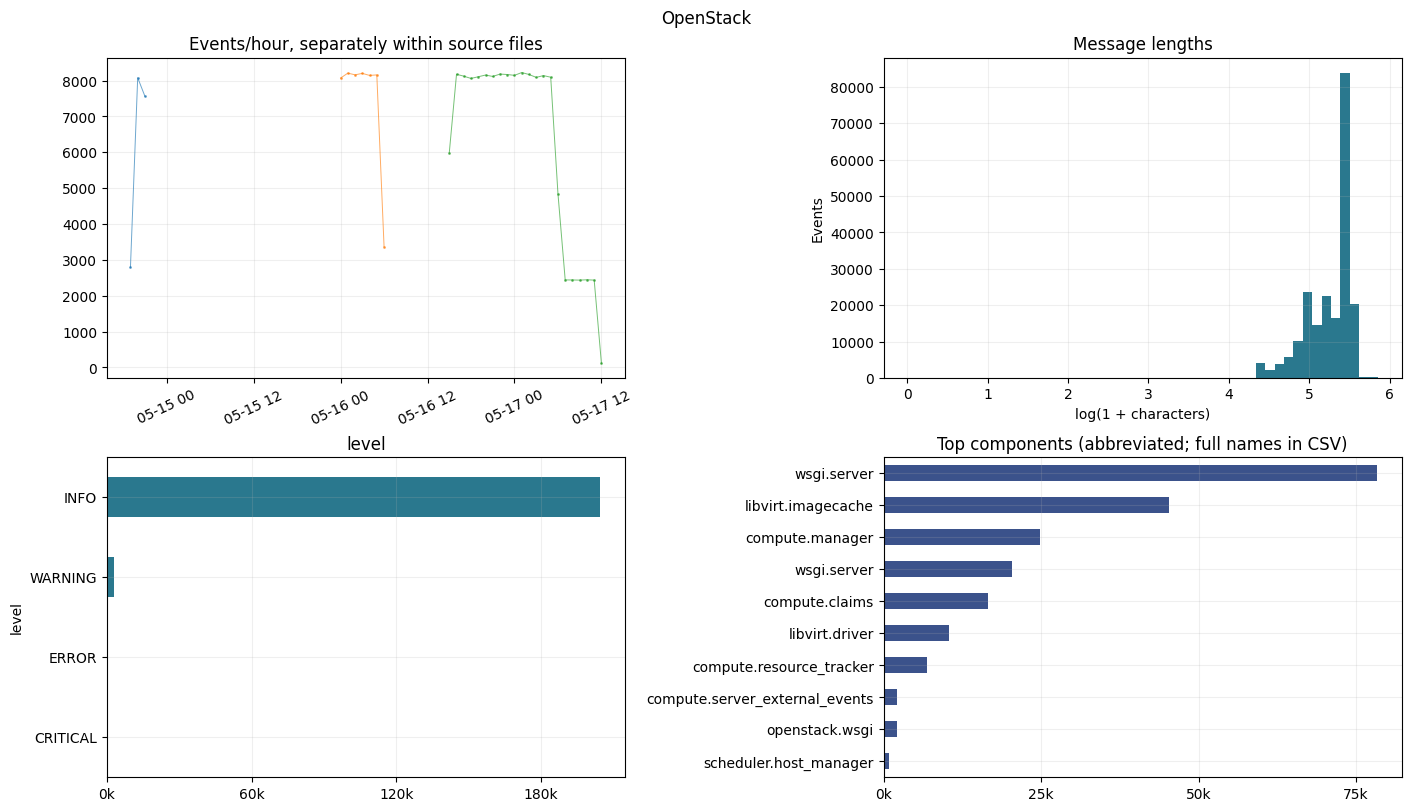

**level_daily_share**

level,CRITICAL,ERROR,INFO,WARNING
timestamp,,,,
2017-05-14,0.0,0.0000,0.9851,0.0149
2017-05-16,0.0,0.0012,0.9826,0.0162
2017-05-17,0.0,0.0007,0.9865,0.0128


**component_daily_share**

component,nova.api.openstack.compute.server_external_events,nova.compute.claims,nova.compute.manager,nova.compute.resource_tracker,nova.metadata.wsgi.server,nova.osapi_compute.wsgi.server,nova.virt.libvirt.driver,nova.virt.libvirt.imagecache
timestamp,,,,,,,,
2017-05-14,0.0108,0.0863,0.1299,0.0297,0.1039,0.4143,0.0541,0.1710
2017-05-16,0.0108,0.0865,0.1296,0.0294,0.1068,0.4091,0.0541,0.1737
2017-05-17,0.0085,0.0684,0.1027,0.0437,0.0853,0.3244,0.0428,0.3242


In [15]:
for column in ["level", "component", "host", "resource", "event_type", "pid", "thread", "capture", "format_variant"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column])
plot_overview(bundle, OUT)
for column in ["level_daily_share", "component_daily_share", "host_daily_share"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 12)

### 6. Что пишут в логах

Смотрю, какие операции чаще всего повторяются и что попадает в самые длинные сообщения. Слова, пары слов и имена компонентов считаю на той же по размеру случайной выборке, что и для Hadoop.

In [16]:
for table in ["common_messages", "rare_messages", "longest_messages", "words_sample", "bigrams_sample", "component_mentions_sample"]:
    display(Markdown("**" + table + "**"))
    show_table(t[table], 30)

**common_messages**

,message,count
0,"[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] image 0673dd71-34c5-4fbb-86c4-40623fbe45b4 at (/var/lib/nova/instances/_base/a489c868f0c37da93b76227c91bb03908ac0e742): in use: on this node 1 local, 0 on other nodes sharing this instance storage",12043
1,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] image 0673dd71-34c5-4fbb-86c4-40623fbe45b4 at (/var/lib/nova/instances/_base/a489c868f0c37da93b76227c91bb03908ac0e742): checking,12043
2,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Active base files: /var/lib/nova/instances/_base/a489c868f0c37da93b76227c91bb03908ac0e742,12035
3,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Unknown base file: /var/lib/nova/instances/_base/a489c868f0c37da93b76227c91bb03908ac0e742,3059
4,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Removable base files: /var/lib/nova/instances/_base/a489c868f0c37da93b76227c91bb03908ac0e742,3059
5,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Removing base or swap file: /var/lib/nova/instances/_base/a489c868f0c37da93b76227c91bb03908ac0e742,2064
6,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Compute_service record updated for cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us:cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us,1739
7,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Auditing locally available compute resources for node cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us,1739
8,[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Final resource view: name=cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us phys_ram=64172MB used_ram=2560MB phys_disk=15GB used_disk=20GB total_vcpus=16 used_vcpus=1 pci_stats=[],1357
9,"[req-addc1839-2ed5-4778-b57e-5854eb7b8b09 - - - - -] Total usable vcpus: 16, total allocated vcpus: 1",1357


**rare_messages**

,message,count
0,"[req-dd1a48ad-a598-4d6d-8cb3-fb67367ab36e 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2577410",1
1,"[req-800c5a87-234d-4e38-9847-ffdea2809d17 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2626259",1
2,"[req-8a0a217f-d13e-4727-a12b-6ccccd655b7b 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2573040",1
3,[req-3ea4052c-895d-4b64-9e2d-04d64c4d94ab - - - - -] [instance: 2d33540d-2191-4695-9d6a-aa745ef9a1a9] VM Started (Lifecycle Event),1
4,[req-3ea4052c-895d-4b64-9e2d-04d64c4d94ab - - - - -] [instance: 2d33540d-2191-4695-9d6a-aa745ef9a1a9] VM Paused (Lifecycle Event),1
5,"[req-52fdc001-8373-4c65-907b-c381fdf617c3 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2576640",1
6,"[req-8c8a1b6f-e2a1-48d1-9b18-db0fc88bb40c 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.3831849",1
7,"[req-1970b24a-257b-46cc-abdb-c26b490000b2 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2737329",1
8,"[req-79b0ae31-b2c8-4c73-89fd-ddb97f365313 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2728212",1
9,"[req-71578a46-678c-4b82-b6db-9b6d55f5daf5 113d3a99c3da401fbd62cc2caa5b96d2 54fadb412c4e40cdbaed9335e4c35a9e - - -] 10.11.10.1 ""GET /v2/54fadb412c4e40cdbaed9335e4c35a9e/servers/detail HTTP/1.1"" status: 200 len: 1893 time: 0.2497010",1


**longest_messages**

,source_file,line_start,message_length,message
812,openstack_abnormal.log,813,349,"[req-aff52c61-eecf-4fd8-8b84-b7060bd8e809 d16a600c5e2a47fe98aee00ee4cb9743 e9746973ac574c6b8a9e8857f56a7608 - - -] 10.11.10.2 ""GET /v2/e9746973ac574c6b8a9e8857f56a7608/servers/detail?all_tenants=True&changes-since=2017-05-15T01%3A35%3A11.378343%2B00%3A00&host=cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/1.1"" status: 200 len: 15552 time: 0.2255919"
2149,openstack_abnormal.log,2150,349,"[req-79a070cd-1d83-4bbb-8766-c5d650de1ea2 d16a600c5e2a47fe98aee00ee4cb9743 e9746973ac574c6b8a9e8857f56a7608 - - -] 10.11.10.2 ""GET /v2/e9746973ac574c6b8a9e8857f56a7608/servers/detail?all_tenants=True&changes-since=2017-05-15T01%3A45%3A11.377790%2B00%3A00&host=cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/1.1"" status: 200 len: 23370 time: 0.3159041"
3511,openstack_abnormal.log,3512,349,"[req-080b7e19-b865-41bc-896c-38ad8d761a03 d16a600c5e2a47fe98aee00ee4cb9743 e9746973ac574c6b8a9e8857f56a7608 - - -] 10.11.10.2 ""GET /v2/e9746973ac574c6b8a9e8857f56a7608/servers/detail?all_tenants=True&changes-since=2017-05-15T01%3A55%3A11.379032%2B00%3A00&host=cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/1.1"" status: 200 len: 23222 time: 0.2493129"
4831,openstack_abnormal.log,4832,349,"[req-15ad477d-d8db-4e16-8a03-48c7ed2ac2ba d16a600c5e2a47fe98aee00ee4cb9743 e9746973ac574c6b8a9e8857f56a7608 - - -] 10.11.10.2 ""GET /v2/e9746973ac574c6b8a9e8857f56a7608/servers/detail?all_tenants=True&changes-since=2017-05-15T02%3A05%3A11.382350%2B00%3A00&host=cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/1.1"" status: 200 len: 23369 time: 0.3119249"
6191,openstack_abnormal.log,6192,349,"[req-853ae724-fd67-4204-8ab4-bdec8328f321 d16a600c5e2a47fe98aee00ee4cb9743 e9746973ac574c6b8a9e8857f56a7608 - - -] 10.11.10.2 ""GET /v2/e9746973ac574c6b8a9e8857f56a7608/servers/detail?all_tenants=True&changes-since=2017-05-15T02%3A15%3A11.385371%2B00%3A00&host=cp-1.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/1.1"" status: 200 len: 23222 time: 0.2577951"


... (2 outputs left out)

**bigrams_sample**

,token,count
0,fadb cdbaed,86733
1,fbd caa,51351
2,caa fadb,51351
3,http status,47630
4,status len,47630
5,len time,47630
6,cdbaed servers,35379
7,cdbaed get,33369
8,get fadb,33369
9,servers detail,32551


**component_mentions_sample**

,source_component,mentioned_component,messages


### 7. Адреса и идентификаторы

Помимо адресов и путей здесь интересны `request_id` и `instance_id`. Первый помогает связать строки одного запроса, второй позволяет искать события конкретной виртуальной машины.

In [17]:
show_table(t["entities"], 20)
show_table(t["entity_examples"], 80)
for column in ["session_id", "request_id", "instance_id", "numeric_flag"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 15)

,entity,unique,mentions
0,url,0,0
1,uuid,94541,276261
2,ipv4,2066,119136
3,port,0,0
4,path,4181,148263
5,hash,7,354636
6,device,0,0
7,session_candidate,90406,192174


,entity,value,mentions
0,uuid,addc1839-2ed5-4778-b57e-5854eb7b8b09,52349
1,uuid,0673dd71-34c5-4fbb-86c4-40623fbe45b4,24230
2,uuid,3ea4052c-895d-4b64-9e2d-04d64c4d94ab,12248
3,uuid,daf38630-e1ca-42b1-8b71-4df078076a47,32
4,uuid,74e32610-53a0-4e61-9125-83f6edc60a90,32
5,uuid,16797a0f-32fb-494c-8f36-38588148c35d,32
6,uuid,ac7c329c-1a20-4735-bf9a-b15102f1c44d,32
7,uuid,0c28eea9-14ec-4f20-ad24-1cf8a2c5975d,32
8,uuid,2a841e49-df08-45c9-b387-003e2e28fc0d,32
9,uuid,6fc3fd6d-f9fa-4daf-8199-70b455b4ac58,32


**request_id**

,count,share_pct
request_id,,
addc1839-2ed5-4778-b57e-5854eb7b8b09,52349,25.190
<missing>,15646,7.529
3ea4052c-895d-4b64-9e2d-04d64c4d94ab,12248,5.894
e4180e2e-aa4b-47e1-baa6-390140ea9be8,12,0.006
987e906c-1738-4040-b368-ddc7ac50f7f4,12,0.006
e9b02576-ad5d-4efa-8484-7fa30fe71862,12,0.006
68df73ee-4a55-4209-a294-0ee70f59ed2a,12,0.006
f7a8bb77-7f4e-45c9-b3b2-650667f5d95c,12,0.006
1b746c0e-31a3-481c-b9d9-290d6394a480,12,0.006


**instance_id**

,count,share_pct
instance_id,,
<missing>,150072,72.212
8f461f4f-9e0e-422a-8266-be2671d16abe,30,0.014
d9cc331c-7c5d-4507-89de-1d78c3b0bddc,30,0.014
1dbcdff4-2bc2-431f-9444-b2e855d74da5,29,0.014
bf8c824d-f099-4433-a41e-e3da7578262e,29,0.014
1f7fe6d0-3c1f-4238-9277-8b6b59419607,29,0.014
e11f4db2-3c9a-4e62-97b6-4b15387729bd,29,0.014
3ee6b0f3-c1c3-4e77-be21-a206cab4b4ee,29,0.014
5f2d279b-0e0b-43aa-875e-051fe2d00788,29,0.014


### 8. Шаблоны сообщений

Применяю те же правила замены переменных частей, что и для Hadoop. Смотрю, какие формулировки повторяются и когда они встречались в этих трёх прогонах.

In [18]:
show_table(t["templates_common"], 20)
show_table(t["templates_rare"], 15)
show_table(t["template_endpoints"], 16)

,template,count
0,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path> HTTP/<num>"" status: <num> len: <num> time: <num>",67509
1,"[req-<uuid> - - - - -] image <uuid> at (<path>): in use: on this node <num> local, <num> on other nodes sharing this instance storage",12043
2,[req-<uuid> - - - - -] image <uuid> at (<path>): checking,12043
3,[req-<uuid> - - - - -] Active base files: <path>,12035
4,"[req-<uuid> - - - - -] <ipv4>,<ipv4> ""GET <path> HTTP/<num>"" status: <num> len: <num> time: <num>",9730
5,"[-] <ipv4>,<ipv4> ""GET <path> HTTP/<num>"" status: <num> len: <num> time: <num>",7455
6,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""POST <path> HTTP/<num>"" status: <num> len: <num> time: <num>",6194
7,[req-<uuid> - - - - -] [instance: <uuid>] VM Resumed (Lifecycle Event),4132
8,[req-<uuid> - - - - -] [instance: <uuid>] During sync_power_state the instance has a pending task (spawning). Skip.,3984
9,[req-<uuid> - - - - -] Unknown base file: <path>,3059


,template,count
0,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A15%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1
1,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A24%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1
2,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A25%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1
3,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A34%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1
4,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A35%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1
5,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A44%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1
6,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A45%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1
7,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A54%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1
8,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T15%3A55%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1
9,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T16%3A04%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1


,template,count,first_seen,last_seen,span_seconds,selection
0,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A45%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:55:11.889,2017-05-17 11:55:11.889,0.0,latest first appearance
1,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A44%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:55:01.004,2017-05-17 11:55:01.004,0.0,latest first appearance
2,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A35%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:45:11.890,2017-05-17 11:45:11.890,0.0,latest first appearance
3,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A34%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:44:58.483,2017-05-17 11:44:58.483,0.0,latest first appearance
4,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A25%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:35:11.890,2017-05-17 11:35:11.890,0.0,latest first appearance
5,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A24%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:34:58.808,2017-05-17 11:34:58.808,0.0,latest first appearance
6,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A15%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:25:12.052,2017-05-17 11:25:12.052,0.0,latest first appearance
7,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-17T17%3A14%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-17 11:24:58.545,2017-05-17 11:24:58.545,0.0,latest first appearance
8,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-15T01%3A34%3A58.<num>%2B00%3A00 HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-14 19:44:58.492,2017-05-14 19:44:58.492,0.0,earliest last appearance
9,"[req-<uuid> <hash> <hash> - - -] <ipv4> ""GET <path>?all_tenants=True&changes-since=<num>-<num>-15T01%3A35%3A11.<num>%2B00%3A00&host=cp-<num>.slowvm1.tcloud-pg0.utah.cloudlab.us HTTP/<num>"" status: <num> len: <num> time: <num>",1,2017-05-14 19:45:11.608,2017-05-14 19:45:11.608,0.0,earliest last appearance


### 9. Разметка и примеры

Сопоставляю записи с явным упоминанием четырёх машин и записи контрольных прогонов. Остальные строки из файла `abnormal` остаются с неизвестным статусом. В примерах видно, какие операции связаны с этими машинами. По таблице уровней можно проверить, как часто `ERROR` встречается в контрольных логах.

В таблице эпизодов соседние записи по одной машине объединяются в пределах файла при паузе до минуты. Это даёт отрезок активности в логе, по которому можно найти исходные события.

,instance_id,context_label
0,1643649d-2f42-4303-bfcd-7798baec19f9,injected VM
1,544fd51c-4edc-4780-baae-ba1d80a0acfc,injected VM
2,a445709b-6ad0-40ec-8860-bec60b6ca0c2,injected VM
3,ae651dff-c7ad-43d6-ac96-bbcd820ccca8,injected VM


**label_units**

,labelled_units,share_pct
context_label,,
injected VM,4,100.0


**session_summary**

,instance_id,events,first_seen,last_seen
0,1643649d-2f42-4303-bfcd-7798baec19f9,28,2017-05-14 21:46:48.622,2017-05-14 21:47:43.028
1,544fd51c-4edc-4780-baae-ba1d80a0acfc,28,2017-05-14 21:07:37.102,2017-05-14 21:08:42.508
2,a445709b-6ad0-40ec-8860-bec60b6ca0c2,28,2017-05-14 21:42:42.319,2017-05-14 21:43:56.880
3,ae651dff-c7ad-43d6-ac96-bbcd820ccca8,28,2017-05-14 21:08:40.907,2017-05-14 21:09:33.816


**context_label**

... (7 outputs left out)

**failure_context_episodes**

,source_file,session,start,end,seconds,events
0,openstack_abnormal.log,1643649d-2f42-4303-bfcd-7798baec19f9,2017-05-14 21:46:48.622,2017-05-14 21:47:43.028,54.406,28
1,openstack_abnormal.log,544fd51c-4edc-4780-baae-ba1d80a0acfc,2017-05-14 21:07:37.102,2017-05-14 21:08:42.508,65.406,28
2,openstack_abnormal.log,a445709b-6ad0-40ec-8860-bec60b6ca0c2,2017-05-14 21:42:42.319,2017-05-14 21:43:56.880,74.561,28
3,openstack_abnormal.log,ae651dff-c7ad-43d6-ac96-bbcd820ccca8,2017-05-14 21:08:40.907,2017-05-14 21:09:33.816,52.909,28


**templates_context_exclusive**

,context,template,count
0,normal context only,,8
1,normal context only,Command: <path> -m oslo_concurrency.prlimit --as=<num> --cpu=<num> -- env LC_ALL=C LANG=C qemu-img info <path>/<uuid><path>,8
2,normal context only,Exit code: <num>,8
3,normal context only,"File ""<path>"", line <num>, in _age_and_verify_cached_images",8
4,normal context only,"File ""<path>"", line <num>, in _list_backing_images",8
5,normal context only,"File ""<path>"", line <num>, in _run_image_cache_manager_pass",8
6,normal context only,"File ""<path>"", line <num>, in get_disk_backing_file",8
7,normal context only,"File ""<path>"", line <num>, in manage_image_cache",8
8,normal context only,"File ""<path>"", line <num>, in qemu_img_info",8
9,normal context only,"File ""<path>"", line <num>, in run_periodic_tasks",8


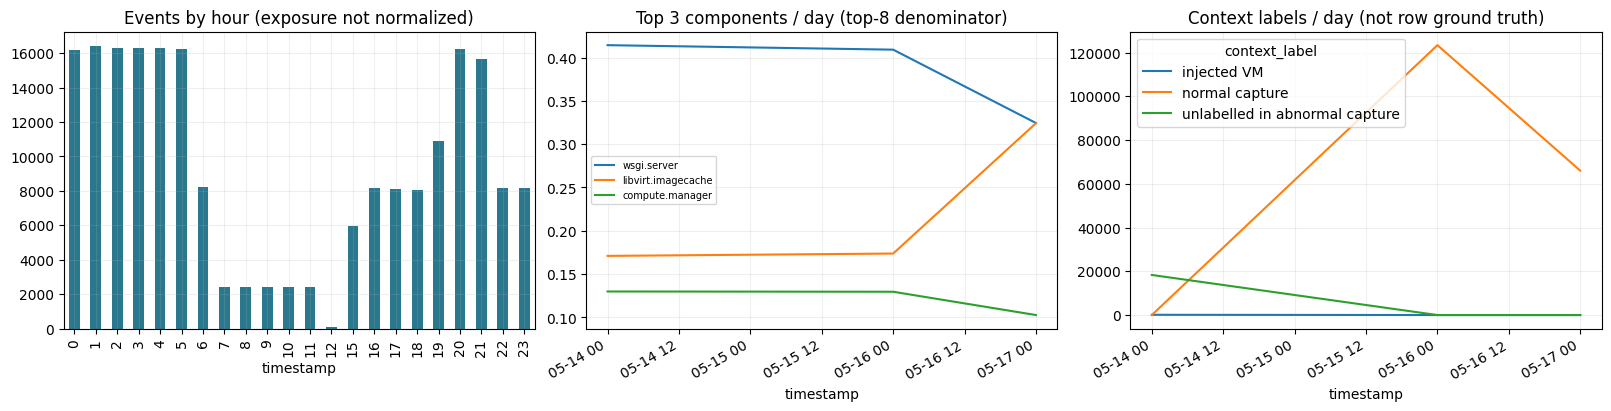

In [19]:
if bundle.labels.empty:
    display(Markdown("В архиве нет подтверждённых меток аномалий; качество детектора по этим данным оценить нельзя."))
else:
    show_table(t["labels_source"], 60)
    for table in ["label_units", "session_summary", "context_label", "label_comparison", "level_by_label", "anomaly_examples", "failure_context_episodes", "templates_context_exclusive"]:
        if table in t:
            display(Markdown("**" + table + "**"))
            show_table(t[table], 15)
plot_dynamics(bundle, result, OUT)

### 10. Временные окна

Считаю события за минуту, пять минут, час и сутки. У каждого из трёх прогонов свои границы, поэтому промежуток между прогонами в число пустых окон не входит.

In [20]:
show_table(t["windows"])
assert int(df.physical_lines.sum()) == bundle.quality["physical_lines"]
assert int(df.parse_ok.sum()) + int((~df.parse_ok).sum()) == len(df)
assert len(bundle.raw_first) == min(100, bundle.quality["physical_lines"])
assert len(bundle.raw_random) == min(100, bundle.quality["physical_lines"])
print("Учёт исходных строк и размеры выборок проверены.")

,window,windows,empty,empty_pct,mean,median,p99,max
0,1min,1772,0,0.0,117.280,132.0,158.00,174
1,5min,357,0,0.0,582.129,673.0,710.76,724
2,1h,32,0,0.0,6494.375,8100.5,8219.04,8224
3,1D,4,0,0.0,51955.000,59158.5,70917.08,71069


Учёт исходных строк и размеры выборок проверены.


### 11. Что получилось на OpenStack

В трёх файлах 207 820 строк, по одному событию на строку. Точных дублей, пропусков времени и скачков назад внутри файла не нашлось. Все прогоны уложились в период с 14 по 17 мая 2017 года.

Из 433 шаблонов десять самых частых покрывают 66,49% событий. Самая загруженная минута содержит 174 события. Внутри прогонов пустых минут не было.

В 112 событиях явно упоминается одна из четырёх размеченных машин. Для ещё 18 322 событий из прогона со сбоями связь с этими машинами не установлена. Среди упоминаний есть обычные операции, например сообщения о выделении ресурсов. `ERROR` встречается и в контрольных логах. Для оценки детектора я бы сначала договорился, что считать одним примером — машину или запрос, — и разделил данные по прогонам.

In [21]:
del df, bundle, result, t
gc.collect()

28235

## Android

### 1. Откуда данные

В `Android.tar.gz` лежит Android_v1, логи Application Framework со смартфона, на котором собирали диагностические данные. В архиве есть PID, TID и тег компонента. Разметки аномалий и идентификатора хоста нет.

Время записано с точностью до миллисекунд, но без года и часового пояса. Для подсчёта интервалов подставляю условный високосный 2000 год. Для дня недели или даты сбора такой календарь использовать нельзя. Если попадётся запись через Новый год, этот переход нужно будет обработать отдельно.

[Описание Android в LogHub](https://github.com/logpai/loghub/tree/master/Android)

In [22]:
NAME = 'Android'
bundle = load_loghub(NAME, DATA_DIR, seed=SEED)
df = bundle.events
OUT = REPORT_DIR / NAME
result = analyze(bundle, OUT, seed=SEED)
t = result["tables"]
SUMMARIES.append(result["summary"])
display(pd.Series(bundle.manifest))
show_table(pd.DataFrame([result["summary"]]))

dataset                                                          Android
archive_md5                             1a1bac1cf0ea95bc88e296f689f0258f
archive_url            https://zenodo.org/api/records/3227177/files/A...
source_url             https://github.com/logpai/loghub/tree/master/A...
scope                                full archive; no sampling of events
seed                                                                  42
timestamp_semantics    month-day, milliseconds; year and timezone una...
dtype: object

,dataset,duplicate_physical_lines,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,missing_tag_separator,logical_events,timestamp_missing,start,end,unique_templates,top10_template_share_pct,mean_message_length,singleton_messages,files,sample_text_events,backwards_steps,duplicate_timestamps_within_files
0,Android,137801,1555005,188665469,64,0,0,1555005,0,64,1555005,0,2000-12-17 19:31:36.263000,2000-12-18 19:53:49.423000,71109,17.124,70.339,232692,1,100000,418,914092


### 2–3. Файл и первые строки

При просмотре обращаю внимание на строки, где нет разделителя между тегом и сообщением. Время, PID, TID и уровень в них читаются. Компонент записываю как `unknown`, остальной текст сохраняю в сообщении и отмечаю такой вариант формата отдельно.

In [23]:
show_table(t["files"], 12)
show_table(t["quality"], 30)
show_table(t["lengths"])
show_table(t["text_summary"], 20)
show_table(t["unparsed"])
show_raw(t["first_100"], "Первые 100 физических строк (в порядке файлов и строк)")
show_raw(t["random_100"], "100 физических строк: reservoir sampling по всему корпусу, seed=42")

,source_file,bytes,sha256,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,missing_tag_separator
0,Android.log,192270829,0f35aa11b67ec07cd34950e5c518961cb841ec0925ce007f16f3eeb0a7d35a07,1555005,188665469,64,0,0,1555005,0,64


,value
metric,
duplicate_physical_lines,137801
physical_lines,1555005
physical_characters,188665469
lines_without_standard_header,64
blank_lines,0
invalid_utf8_lines,0
crlf_lines,1555005
missing_final_newline,0
missing_tag_separator,64


,count,mean,std,min,50%,90%,99%,max
raw_length,1555005.0,121.327886,73.057168,43.0,104.0,205.0,372.0,4100.0
message_length,1555005.0,70.338532,72.146521,0.0,51.0,162.0,328.0,4050.0
physical_lines,1555005.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


,value
metric,
unique_messages,2.672020e+05
singleton_messages,2.326920e+05
duplicate_logical_messages,1.287803e+06
mean_physical_line_chars,1.213280e+02
digits_chars,1.312844e+07
digits_share_pct,1.200300e+01
letters_chars,7.666477e+07
letters_share_pct,7.009200e+01
punctuation_chars,1.156623e+07


,source_file,line_start,message


### 4. Время

Проверяю порядок записей и паузы внутри файла. В таблице будет условный 2000 год, поэтому здесь важны интервалы, а не абсолютные даты.

In [24]:
show_table(t["time_by_file"], 12)
show_table(t["largest_gaps"], 12)
show_table(df.loc[df.timestamp.isna(), ["source_file", "line_start", "time", "message"]], 10)

,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
0,Android.log,2000-12-17 19:31:36.263,2000-12-18 19:53:49.423,418,914092,1283.542,0.002


,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
0,Android.log,2000-12-17 19:31:36.263,2000-12-18 19:53:49.423,418,914092,1283.542,0.002


,source_file,line_start,time,message


### 5. Объём и распределения

Смотрю, в какие часы лог был активнее и какие компоненты, процессы и потоки писали чаще всего. Для сравнения по дням считаю доли среди восьми самых частых компонентов.

**level**

,count,share_pct
level,,
I,766146,49.270
D,505608,32.515
E,157829,10.150
W,80882,5.201
V,44408,2.856
F,132,0.008


**component**

,count,share_pct
component,,
SDK,133646,8.595
PowerManagerService,75836,4.877
HwCustMobileSignalControllerImpl,55644,3.578
wpa_supplicant,53279,3.426
HwSignalClusterView,38672,2.487
amsnl,30409,1.956
libteec,29722,1.911
UsbDeviceManager,28579,1.838
SendBroadcastPermission,24563,1.580


**pid**

,count,share_pct
pid,,
1795,488930,31.442
2852,352089,22.642
633,155938,10.028
5224,42253,2.717
5157,36871,2.371
3218,36738,2.363
3626,35235,2.266
3858,30836,1.983
24266,26831,1.725


**thread**

,count,share_pct
thread,,
2852,298454,19.193
31870,81988,5.273
1795,61196,3.935
5157,35624,2.291
5283,34435,2.214
2323,32141,2.067
4126,30831,1.983
3556,26262,1.689
1825,23919,1.538


**format_variant**

,count,share_pct
format_variant,,
<missing>,1554941,99.996
missing_tag_separator,64,0.004


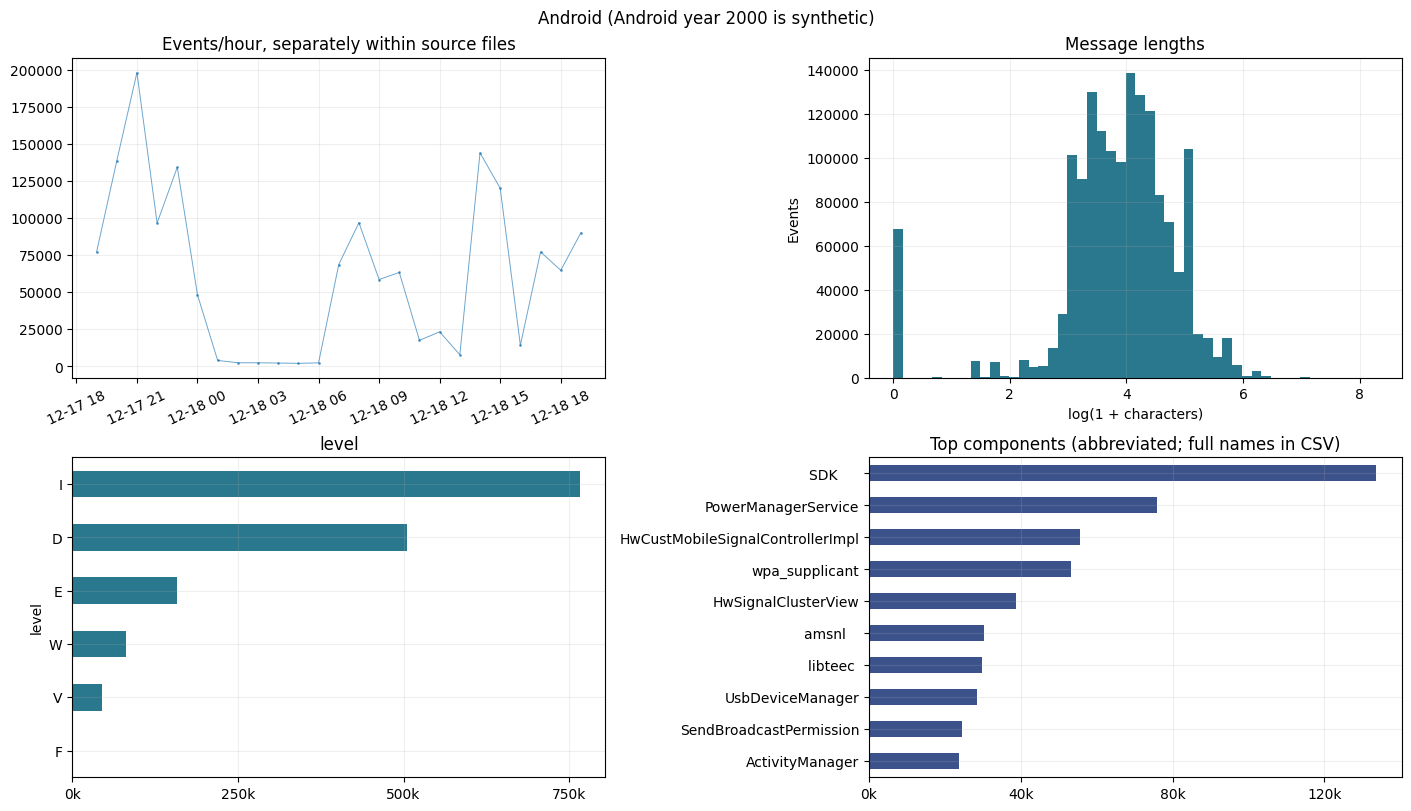

**level_daily_share**

level,D,E,F,I,V,W
timestamp,,,,,,
2000-12-17,0.3047,0.0925,0.0000,0.5207,0.0327,0.0494
2000-12-18,0.3396,0.1079,0.0001,0.4729,0.0256,0.0539


**component_daily_share**

component,HwCustMobileSignalControllerImpl,HwSignalClusterView,PowerManagerService,SDK,UsbDeviceManager,amsnl,libteec,wpa_supplicant
timestamp,,,,,,,,
2000-12-17,0.1197,0.0842,0.1446,0.3811,0.0392,0.0767,0.0727,0.0818
2000-12-18,0.1285,0.0886,0.1883,0.2417,0.0819,0.0621,0.0624,0.1465


In [25]:
for column in ["level", "component", "host", "resource", "event_type", "pid", "thread", "capture", "format_variant"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column])
plot_overview(bundle, OUT)
for column in ["level_daily_share", "component_daily_share", "host_daily_share"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 12)

### 6. Что пишут в логах

Сравниваю длины сообщений и смотрю, какие строки повторяются, а какие встретились один раз. Частые слова, пары слов и упоминания компонентов беру из случайной выборки.

In [26]:
for table in ["common_messages", "rare_messages", "longest_messages", "words_sample", "bigrams_sample", "component_mentions_sample"]:
    display(Markdown("**" + table + "**"))
    show_table(t[table], 30)

**common_messages**

,message,count
0,,67727
1,isCurrentBySim()=false,27822
2,"getTempInfo error: null, 0",22160
3,getOrInflateState subId:0,19120
4,"ready=true,policy=0,wakefulness=0,wksummary=0x1,uasummary=0x0,bootcompleted=true,boostinprogress=false,waitmodeenable=false,mode=true,manual=33,auto=-1,adj=0.0userId=0",13972
5,"presently, hw_update_color_temp_for_rg_led interface not achieved.",11012
6,[HME_JPEG_DEC_Delete](3298): HME_JPEG_DEC_Delete: decoder_ctx=null,10955
7,"ready=true,policy=3,wakefulness=1,wksummary=0x1,uasummary=0x1,bootcompleted=true,boostinprogress=false,waitmodeenable=false,mode=true,manual=33,auto=-1,adj=0.0userId=0",10175
8,"apply hwPhoneState.mSubId:0 anyMobileVisible:false mIsAirplaneMode:false, mobileGroupVisible=true",9992
9,mVSimCurCardType is -1,9992


**rare_messages**

,message,count
0,20002302|before compensate: cache step_5788,1
1,20002302|compensate 24699613 16,1
2,20002302|after compensate: cache step_5789,1
3,20002302|before compensate: cache step_5789,1
4,20002302|compensate 24699613 17,1
5,20002302|after compensate: cache step_5790,1
6,20002302|REPORT : 5790 123640 4123 0,1
7,onStepCounterChange stepsNum:5790,1
8,20002302|upDateHealthNotification()|124|4.12|5790,1
9,"onNotificationPosted: StatusBarNotification(pkg=com.huawei.health user=UserHandle{0} id=10010 tag=null key=0|com.huawei.health|10010|null|10099: Notification(pri=0 contentView=null vibrate=null sound=null defaults=0x0 flags=0x62 color=0x00000000 vis=PRIVATE)) important=2, post=1481976789371, when=1481531589202, vis=0, userid=0",1


**longest_messages**

,source_file,line_start,message_length,message
777767,Android.log,777768,4050,"HsmStat_event:""1008"",""PKG=cn.wps.moffice_eng:COUNT=488,PKG=com.Qunar:COUNT=190,PKG=com.netease.newsreader.activity:COUNT=811,PKG=com.sina.weibo:COUNT=660,PKG=com.ss.android.article.news:COUNT=662,PKG=com.achievo.vipshop:COUNT=287,PKG=com.autonavi.minimap:COUNT=245,PKG=com.huawei.gamebox:COUNT=962,PKG=com.huawei.lives:COUNT=117,PKG=com.huawei.remoteassistant:COUNT=112,PKG=com.vmall.client:COUNT=112,PKG=com.icbc:COUNT=1,PKG=com.tencent.qqmusic:COUNT=1,PKG=com.huawei.vdrive:COUNT=47,PKG=com.tmall.w…"
160962,Android.log,160963,4026,"org.iqiyi.video.h.bs.a()<-1> : reflaction getDataFromNetwork + {""code"":0,""base"":{""name"":""phone播放页3.0"",""page_name"":""播放页"",""page_t"":""player_tabs"",""page_v"":""3.0"",""exp_time"":5,""has_next"":1,""next_url"":""http://iface2.iqiyi.com/views_sns/3.0/paopao_feeds?tvid=575628500&categoryid=2&wallId=209066947&paopao_device_id=0&tvct=1&albumid=203364601"",""category_id"":""2"",""statistics"":{""block"":""504092_ply"",""from_category_id"":""2"",""mod"":""cn_s"",""purl"":""203364601"",""rpage"":""player_tabs"",""rpage_dict"":{""half"":""half_ply"",""…"
264760,Android.log,264761,4023,"WidgetCustomizeContainer all widgets =[AppWidgetProviderInfo(UserHandle{0}/ComponentInfo{cn.wps.moffice_eng/cn.wps.widget.MofficeAppWidgetProvider_4x2}), AppWidgetProviderInfo(UserHandle{0}/ComponentInfo{com.android.calendar/com.android.calendar.widget.CalendarAppWidgetProvider}), AppWidgetProviderInfo(UserHandle{0}/ComponentInfo{com.android.calendar/com.android.calendar.simpleui.CalendarSimpleUiPRovider}), AppWidgetProviderInfo(UserHandle{0}/ComponentInfo{com.android.calendar/com.android.calend…"
154299,Android.log,154300,4019,"onRequestMobileServerSucceeded():tvId: , playerId: qc_100001_100086, from cache: false, json: {""version"":""2.1.11215"",""sei"":"""",""reqTemplateTypes"":[""focus""],""reqTimeouts"":[7000,7000],""midrollPoints"":{},""vipCheckConflict"":{},""pbp"":{""d"":""54000"",""h"":""0"",""l"":""MTE3LjEzNi43OS4xNTU="",""g"":""0""},""ims"":""100"",""requestId"":""60d015759e91f2d81a4fc29b801506d3"",""adSlots"":[{""startTime"":0,""ads"":[{""creativeId"":""5000000976903"",""clickTracking"":{""thirdPartyTracking"":[""http:\/\/tyaqy.m.cn.miaozhen.com\/r\/k=2034249&p=7444…"
261885,Android.log,261886,4019,"onRequestMobileServerSucceeded():tvId: , playerId: qc_100001_100086, from cache: false, json: {""version"":""2.1.11215"",""sei"":"""",""reqTemplateTypes"":[""focus""],""reqTimeouts"":[7000,7000],""midrollPoints"":{},""vipCheckConflict"":{},""pbp"":{""d"":""54000"",""h"":""0"",""l"":""MTE3LjEzNi43OS4xNTU="",""g"":""0""},""ims"":""100"",""requestId"":""814cf65ce421edce4f4437063ca79f2d"",""adSlots"":[{""startTime"":0,""ads"":[{""creativeId"":""5000000976903"",""clickTracking"":{""thirdPartyTracking"":[""http:\/\/tyaqy.m.cn.miaozhen.com\/r\/k=2034249&p=7444…"


... (2 outputs left out)

**bigrams_sample**

,token,count
0,com huawei,5026
1,sec level,4489
2,sdk sec,4311
3,com android,4279
4,mode true,2679
5,warn sdk,2675
6,level warn,2675
7,warn magic,2675
8,magic pubevt_close,2667
9,pubevt_close getting,2667


**component_mentions_sample**

,source_component,mentioned_component,messages
0,StatusBar,Notification,365
1,PowerManager_screenOn,PowerManagerNotifier,361
2,NotificationManager,Notification,157
3,PowerManager_screenOn,DisplayPowerController,149
4,HwPFWLogger,whitelist,129
5,NetdConnector,Tethering,65
6,libc,property,44
7,PowerManager_screenOn,HwPhoneWindowManager,42
8,PowerManager_screenOn,PowerManagerService,30
9,HwSystemManager,SimCardMethod,30


### 7. Адреса и идентификаторы

Проверяю, какие адреса, пути и ID встречаются в тексте. PID и TID помогают различать процессы и потоки, но при повторном запуске те же номера могут встретиться снова.

In [27]:
show_table(t["entities"], 20)
show_table(t["entity_examples"], 80)
for column in ["session_id", "request_id", "instance_id", "numeric_flag"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 15)

,entity,unique,mentions
0,url,304,2904
1,uuid,24,54
2,ipv4,311,5582
3,port,5,1107
4,path,1165,12283
5,hash,165,5103
6,device,0,0
7,session_candidate,4,44


,entity,value,mentions
0,url,"http://pic2.qiyipic.com/image/20161211/9a/b4/a_100018961_m_601_m3_284_160.jpg',",408
1,url,https://service.10046.mi.com/...,177
2,url,"http://eapp.huawei.com/emall/,",116
3,url,"http://3ms.huawei.com/hi/group/2028001/threads.html#category=1136267,",116
4,url,"http://app-inter.huawei.com/AnyContacts/api/v1/userauth/getserverconf,",116
5,url,"http://app-inter.huawei.com/AnyContacts/api/v1/user_call_log/call,",116
6,url,"http://spes.huawei.com/AnyContacts/api/v1/user_call_log/call,",116
7,url,"http://spes.huawei.com/AnyContacts/api/v1/userauth/getserverconf,",116
8,url,"http://m.qiyipic.com/image/20161126/74/66/v_111364706_m_601_320_180.jpg',",72
9,url,"http://cache.video.qiyi.com/vp/574748300/d7b2bc5333c90fa91d8297f30d0dc81c/?src=2_22_222&t=1481526113011&vf=28c615a87e8bd78cd1aff9122d2cc497&vt=1',",72


### 8. Шаблоны сообщений

Здесь особенно интересно, насколько сильно сокращается число разных сообщений после замены чисел, адресов и ID. Смотрю частые и редкие шаблоны и время их появления в пределах этой записи.

In [28]:
show_table(t["templates_common"], 20)
show_table(t["templates_rare"], 15)
show_table(t["template_endpoints"], 16)

,template,count
0,,67815
1,<<num>-<num>-<num> <num>:<num>:<num>> [WARN] SDK: UE-SeC <num>-<num>-<num> <num>:<num>:<num>:<num> Level[WARN] magic[<num> <num>]:PubEvt_Close Getting a socket[<num>] from the Socket-table Failed!,40941
2,"ready=true,policy=<num>,wakefulness=<num>,wksummary=<hex>,uasummary=<hex>,bootcompleted=true,boostinprogress=false,waitmodeenable=false,mode=true,manual=<num>,auto=<num>,adj=<num>.0userId=<num>",36469
3,isCurrentBySim()=false,27822
4,"getTempInfo error: null, <num>",22160
5,WPS: attr type=<hex> len=<num>,19997
6,getOrInflateState subId:<num>,19120
7,"presently, hw_update_color_temp_for_rg_led interface not achieved.",11012
8,[HME_JPEG_DEC_Delete](<num>): HME_JPEG_DEC_Delete: decoder_ctx=null,10955
9,mVSimCurCardType is <num>,9992


,template,count
0,Timeout pkg=com.huawei.betaclub callback=android.app.ITransientNotification$Stub$Proxy@28784b6,1
1,windowsVisibleLocked(): ActivityRecord{23ea235 u0 com.huawei.betaclub/.home.HomeActivity t404} idle: true,1
2,Duplicate finish request for ActivityRecord{5d82a5 u0 com.huawei.betaclub/.feedback.description.common.SpecialFeatureDescriptionActivity t404 f},1
3,"Remove activity client record, r= ActivityRecord{4b6eb3d token=android.os.BinderProxy@d24866e {com.huawei.betaclub/com.huawei.betaclub.feedback.description.common.SpecialFeatureDescriptionActivity}} token= android.os.BinderProxy@d24866e",1
4,"Background sticky concurrent mark sweep GC freed <num>(2MB) AllocSpace objects, <num>(208KB) LOS objects, <num>% free, 54MB/57MB, paused <num>.684ms total <num>.848ms",1
5,[CaptureUtils.captureLogMetricInfo]Start logId:<num>,1
6,[CaptureUtils.captureLogMetricInfo]Start moduleName:null,1
7,[CaptureUtils.captureLogMetricInfo]Start setTime:<num>,1
8,[OtherUtils.isMethodSupportedForObject]methodName/Supported:captureLogMetricWithParameters/true,1
9,[CaptureUtils.getMetricLogInfoWithParameters]Start logId:<num>,1


,template,count,first_seen,last_seen,span_seconds,selection
0,e id:<num> type:{pkg:com.huawei.imonitor},1,2000-12-18 19:53:49.369,2000-12-18 19:53:49.369,0.0,latest first appearance
1,"onEntryAdded:<num>|com.huawei.imonitor|<num>|null|<num>, group=<num>|com.huawei.imonitor|<num>|null|<num>",1,2000-12-18 19:53:49.366,2000-12-18 19:53:49.366,0.0,latest first appearance
2,No peeking: unimportant notification: <num>|com.huawei.imonitor|<num>|null|<num>,1,2000-12-18 19:53:49.366,2000-12-18 19:53:49.366,0.0,latest first appearance
3,addNotification key=<num>|com.huawei.imonitor|<num>|null|<num>,1,2000-12-18 19:53:49.303,2000-12-18 19:53:49.303,0.0,latest first appearance
4,"onNotificationPosted: StatusBarNotification(pkg=com.huawei.imonitor user=UserHandle{<num>} id=<num> tag=null key=<num>|com.huawei.imonitor|<num>|null|<num>: Notification(pri=<num> contentView=null vibrate=null sound=null tick defaults=<hex> flags=<hex> color=<hex> vis=PRIVATE)) important=<num>, post=<num>, when=<num>, vis=<num>, userid=<num>",1,2000-12-18 19:53:49.303,2000-12-18 19:53:49.303,0.0,latest first appearance
5,enqueueNotificationInternal: n.getKey = <num>|com.huawei.imonitor|<num>|null|<num>,1,2000-12-18 19:53:49.296,2000-12-18 19:53:49.296,0.0,latest first appearance
6,enqueueNotificationInternal: pkg=com.huawei.imonitor id=<num> notification=Notification(pri=<num> contentView=null vibrate=null sound=null tick defaults=<hex> flags=<hex> color=<hex> vis=PRIVATE),1,2000-12-18 19:53:49.294,2000-12-18 19:53:49.294,0.0,latest first appearance
7,type: packing; id: <num>; size: <num>; notificationLogId: <num>,1,2000-12-18 19:53:49.286,2000-12-18 19:53:49.286,0.0,latest first appearance
8,remove(PendingIntent{200e965: PendingIntentRecord{7f86237 com.huawei.espacev2 broadcastIntent}}) changed bounds; rebatching,1,2000-12-17 19:31:36.326,2000-12-17 19:31:36.326,0.0,earliest last appearance
9,set(PendingIntent{a9e563a: PendingIntentRecord{7f86237 com.huawei.espacev2 broadcastIntent}}) : type=<num> triggerAtTime=<num> win=<num> tElapsed=<num> maxElapsed=<num> interval=<num> flags=<hex>,1,2000-12-17 19:31:36.329,2000-12-17 19:31:36.329,0.0,earliest last appearance


### 9. Разметка

В архиве нет меток аномалий. По графикам ниже можно найти необычные участки, которые стоит прочитать вручную.

В архиве нет подтверждённых меток аномалий; качество детектора по этим данным оценить нельзя.

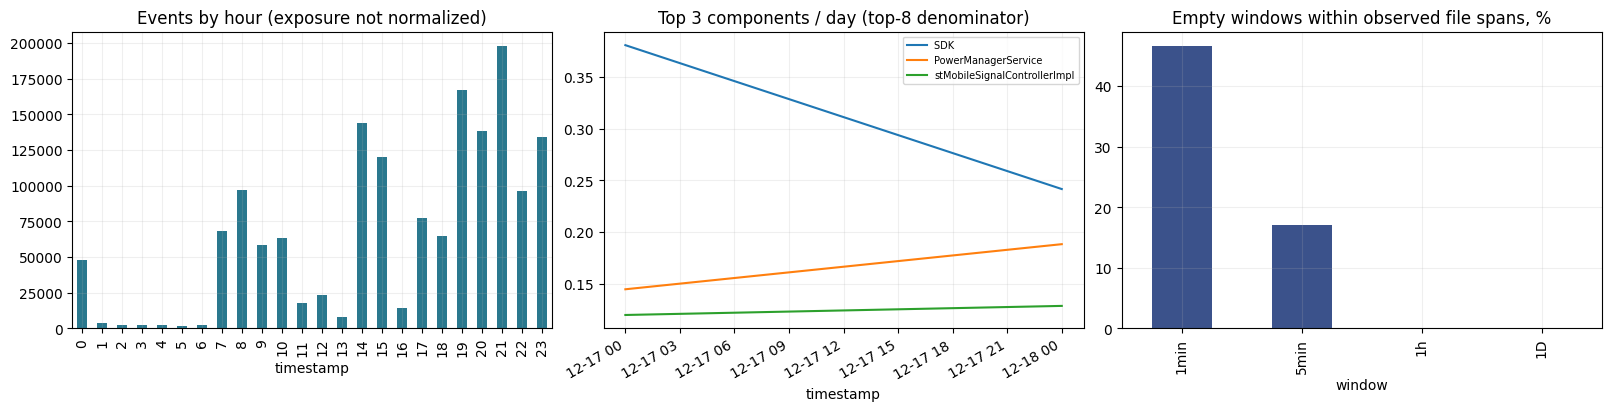

In [29]:
if bundle.labels.empty:
    display(Markdown("В архиве нет подтверждённых меток аномалий; качество детектора по этим данным оценить нельзя."))
else:
    show_table(t["labels_source"], 60)
    for table in ["label_units", "session_summary", "context_label", "label_comparison", "level_by_label", "anomaly_examples", "failure_context_episodes", "templates_context_exclusive"]:
        if table in t:
            display(Markdown("**" + table + "**"))
            show_table(t[table], 15)
plot_dynamics(bundle, result, OUT)

### 10. Временные окна

Смотрю, как меняется доля пустых окон при переходе от минуты к пяти минутам, часу и суткам. На коротком фрагменте особенно важно помнить, что крайние окна могут быть неполными.

In [30]:
show_table(t["windows"])
assert int(df.physical_lines.sum()) == bundle.quality["physical_lines"]
assert int(df.parse_ok.sum()) + int((~df.parse_ok).sum()) == len(df)
assert len(bundle.raw_first) == min(100, bundle.quality["physical_lines"])
assert len(bundle.raw_random) == min(100, bundle.quality["physical_lines"])
print("Учёт исходных строк и размеры выборок проверены.")

,window,windows,empty,empty_pct,mean,median,p99,max
0,1min,1463,683,46.685,1062.888,30.0,11800.62,27208
1,5min,293,50,17.065,5307.184,1211.0,35934.64,88229
2,1h,25,0,0.000,62200.200,63337.0,185157.72,198153
3,1D,2,0,0.000,777502.500,777502.5,907664.63,910321


Учёт исходных строк и размеры выборок проверены.


### 11. Что получилось на Android

В одном файле 1 555 005 строк и столько же событий. Даты удалось извлечь из всех строк, в том числе из 64 без обычного разделителя между тегом и сообщением. Точных повторов текста 137 801. В 418 местах время пошло назад. Лог начинается 17 декабря в 19:31 и заканчивается 18 декабря в 19:53. Год неизвестен.

Разброс по минутам большой. Пустых окон 46,69%, а в самой активной минуте 27 208 событий. Самая длинная пауза заняла около 21 минуты (1 283,542 секунды). По этому фрагменту видно, как менялась активность за сутки. Для вывода о том, повторяется ли этот рисунок каждый день, нужно больше данных.

Получилось 71 109 шаблонов, из которых десять самых частых покрывают всего 17,12% событий. Я бы проверил, даст ли Drain более устойчивые группы, и сохранил бы тег, PID и TID при подготовке признаков.

In [31]:
del df, bundle, result, t
gc.collect()

28283

## HPC

### 1. Откуда данные

Это логи кластера System 20 из Los Alamos National Laboratory. Формат начала строки варьируется. Например, перед именем узла иногда стоит имя демона. Выделяю узлы и устройства `node`, `gige` и `Interconnect`, а также компонент и тип события. Для записи без узнаваемого хоста сохраняю название ресурса отдельно.

Первое поле — ID записи. Время хранится в Unix-секундах, поэтому перевожу его в UTC. Значения `error`, `temperature` и `start` использую как типы событий. Числовое поле после времени, включая отрицательные значения, сохраняю как `numeric_flag`. Его смысл по описанию данных установить не удалось.

[Описание HPC в LogHub](https://github.com/logpai/loghub/tree/master/HPC)

In [32]:
NAME = 'HPC'
bundle = load_loghub(NAME, DATA_DIR, seed=SEED)
df = bundle.events
OUT = REPORT_DIR / NAME
result = analyze(bundle, OUT, seed=SEED)
t = result["tables"]
SUMMARIES.append(result["summary"])
display(pd.Series(bundle.manifest))
show_table(pd.DataFrame([result["summary"]]))

dataset                                                              HPC
archive_md5                             4a7f0483f7b4fdd8b278c266039db464
archive_url            https://zenodo.org/api/records/3227177/files/H...
source_url              https://github.com/logpai/loghub/tree/master/HPC
scope                                full archive; no sampling of events
seed                                                                  42
timestamp_semantics                                    Unix seconds, UTC
dtype: object

,dataset,duplicate_physical_lines,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,logical_events,timestamp_missing,start,end,unique_templates,top10_template_share_pct,mean_message_length,singleton_messages,files,sample_text_events,backwards_steps,duplicate_timestamps_within_files
0,HPC,16817,433490,32686525,0,0,0,433489,1,433490,9,2003-07-31 11:04:04+00:00,2006-04-30 11:28:24+00:00,1161,79.467,26.521,4222,1,100000,227832,158327


### 2–3. Файл и первые строки

По исходным строкам проверяю, как в логе записаны хосты, ресурсы и типы событий. Точные повторы и строки с неполными полями остаются в данных и видны в сводке качества.

In [33]:
show_table(t["files"], 12)
show_table(t["quality"], 30)
show_table(t["lengths"])
show_table(t["text_summary"], 20)
show_table(t["unparsed"])
show_raw(t["first_100"], "Первые 100 физических строк (в порядке файлов и строк)")
show_raw(t["random_100"], "100 физических строк: reservoir sampling по всему корпусу, seed=42")

,source_file,bytes,sha256,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline
0,HPC.log,33553503,6fe9494c4684618541ee03b82f2708fab753443deb5d1e449e473072bdc11181,433490,32686525,0,0,0,433489,1


,value
metric,
duplicate_physical_lines,16817
physical_lines,433490
physical_characters,32686525
lines_without_standard_header,0
blank_lines,0
invalid_utf8_lines,0
crlf_lines,433489
missing_final_newline,1
logical_events,433490


,count,mean,std,min,50%,90%,99%,max
raw_length,433490.0,75.403181,34.389353,43.0,56.0,143.0,167.0,896.0
message_length,433490.0,26.520916,29.354072,0.0,14.0,76.0,104.0,854.0
physical_lines,433490.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


,value
metric,
unique_messages,9966.000
singleton_messages,4222.000
duplicate_logical_messages,423524.000
mean_physical_line_chars,75.403
digits_chars,1134341.000
digits_share_pct,9.867
letters_chars,8673340.000
letters_share_pct,75.443
punctuation_chars,466369.000


,source_file,line_start,message


### 4. Время

Сначала проверяю, идёт ли файл в хронологическом порядке. Затем смотрю совпадающие отметки и самые длинные паузы. Строки с некорректным Unix-временем выведены отдельно, чтобы их можно было найти в файле.

In [34]:
show_table(t["time_by_file"], 12)
show_table(t["largest_gaps"], 12)
show_table(df.loc[df.timestamp.isna(), ["source_file", "line_start", "time", "message"]], 10)

,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
0,HPC.log,2003-07-31 11:04:04+00:00,2006-04-30 11:28:24+00:00,227832,158327,10858359.0,60.0


,source_file,start,end,backwards_steps,duplicate_timestamps,max_gap_seconds,median_positive_gap_seconds
0,HPC.log,2003-07-31 11:04:04+00:00,2006-04-30 11:28:24+00:00,227832,158327,10858359.0,60.0


,source_file,line_start,time,message
78875,HPC.log,78876,1135.5,ClusterFileSystem: ServerFileSystem domain root1_local_backup is no longer served by node node-224
259418,HPC.log,259419,15.560,normal
260378,HPC.log,260379,15.598,normal
260379,HPC.log,260380,15.537,warning
264686,HPC.log,264687,15.571,ambient=24
265736,HPC.log,265737,15.590,ambient=28
265737,HPC.log,265738,15.590,ambient=28
265738,HPC.log,265739,15.530,ambient=28
268193,HPC.log,268194,15.531,ambient=28


### 5. Объём и распределения

Сравниваю, какие хосты и компоненты активнее и какие типы событий встречаются чаще. Для HPC в этой таблице удобнее смотреть `event_type`, так как отдельного стандартного уровня сообщений в данных нет.

**component**

,count,share_pct
component,,
switch_module,131600,30.358
node,113275,26.131
gige,100190,23.112
unix.hw,30086,6.940
action,28591,6.596
clusterfilesystem,15909,3.670
partition,7542,1.740
boot_cmd,3902,0.900
domain,1458,0.336


**host**

,count,share_pct
host,,
gige7,44793,10.333
Interconnect-0N00,29914,6.901
Interconnect-1N01,29569,6.821
gige6,20463,4.721
gige3,14588,3.365
Interconnect-1T01,13957,3.220
<missing>,11969,2.761
Interconnect-1N00,11028,2.544
gige4,9522,2.197


**resource**

,count,share_pct
resource,,
gige7,44793,10.333
Interconnect-0N00,29914,6.901
Interconnect-1N01,29569,6.821
gige6,20463,4.721
gige3,14588,3.365
Interconnect-1T01,13957,3.220
Interconnect-1N00,11028,2.544
gige4,9522,2.197
Interconnect-0N03,9076,2.094


**event_type**

,count,share_pct
event_type,,
temperature,154930,35.740
error,105572,24.354
status,67348,15.536
start,27818,6.417
net.niff.up,23121,5.334
fan,21774,5.023
clusterfilesystem.not_served,8152,1.881
clusterfilesystem.no_server,5126,1.182
bcast-error,3718,0.858


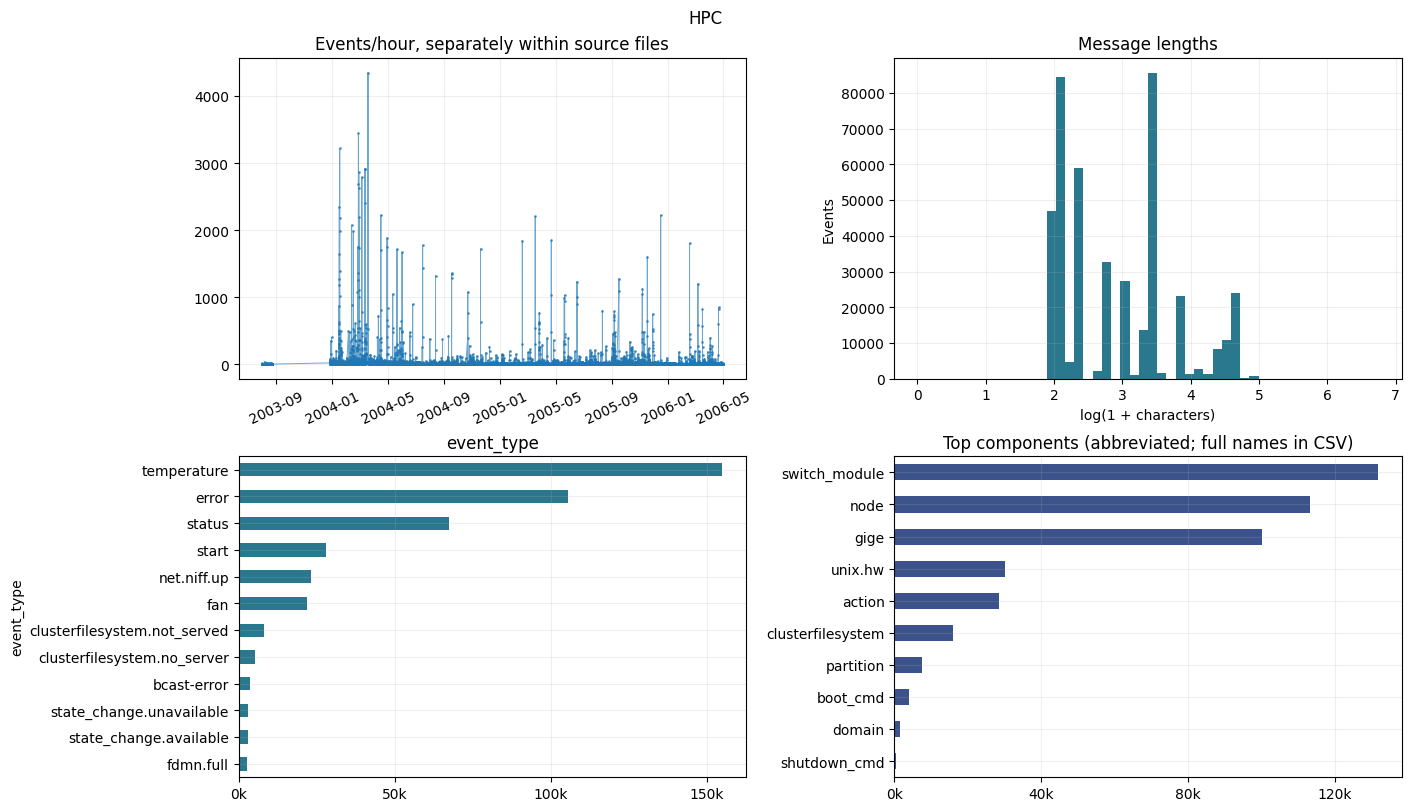

**component_daily_share**

component,action,boot_cmd,clusterfilesystem,gige,node,partition,switch_module,unix.hw
timestamp,,,,,,,,
2003-07-31 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-01 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-02 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-03 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-04 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-05 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0909,0.9091,0.0,0.0
2003-08-06 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-07 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0
2003-08-08 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0000,1.0000,0.0,0.0


**host_daily_share**

host,Interconnect-0N00,Interconnect-1N00,Interconnect-1N01,Interconnect-1T01,gige3,gige4,gige6,gige7
timestamp,,,,,,,,
2003-12-26 00:00:00+00:00,0.0466,0.0363,0.5389,0.0259,0.0052,0.0829,0.0207,0.2435
2003-12-27 00:00:00+00:00,0.0053,0.0000,0.5133,0.0346,0.0718,0.0691,0.0160,0.2899
2003-12-28 00:00:00+00:00,0.0029,0.0000,0.5174,0.0436,0.0291,0.0698,0.0058,0.3314
2003-12-29 00:00:00+00:00,0.0081,0.0000,0.6260,0.0407,0.0596,0.0163,0.0108,0.2385
2003-12-30 00:00:00+00:00,0.0293,0.0171,0.5575,0.0293,0.0562,0.0562,0.0098,0.2445
2003-12-31 00:00:00+00:00,0.0027,0.0000,0.5904,0.0479,0.0532,0.0505,0.0053,0.2500
2004-01-01 00:00:00+00:00,0.0052,0.0000,0.6302,0.0286,0.0182,0.0417,0.0052,0.2708
2004-01-02 00:00:00+00:00,0.0000,0.0000,0.5851,0.0254,0.0072,0.0870,0.0036,0.2917
2004-01-03 00:00:00+00:00,0.0027,0.0000,0.5707,0.0320,0.0160,0.0987,0.0053,0.2747


In [35]:
for column in ["level", "component", "host", "resource", "event_type", "pid", "thread", "capture", "format_variant"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column])
plot_overview(bundle, OUT)
for column in ["level_daily_share", "component_daily_share", "host_daily_share"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 12)

### 6. Что пишут в логах

Смотрю, какие сообщения кластер записывает регулярно и чем они отличаются от редких и длинных строк. Словарь и пары слов считаю на случайной выборке, как в предыдущих разделах.

In [36]:
for table in ["common_messages", "rare_messages", "longest_messages", "words_sample", "bigrams_sample", "component_mentions_sample"]:
    display(Markdown("**" + table + "**"))
    show_table(t[table], 30)

**common_messages**

,message,count
0,Linkerror event interval expired,84894
1,warning,49741
2,normal,45818
3,running,30064
4,configured out,19839
5,link errors remain current,13645
6,Fan speeds ( 3552 3534 3375 **** 3515 3479 ),13374
7,not responding,12367
8,ambient=28,6913
9,ambient=30,6166


**rare_messages**

,message,count
0,Targeting domains:node-D7 and nodes:node-[224-231],1
1,Component State Change: Component \042SCSI-WWID:01000010:6005-08b4-0000-c06e-0001-4000-0062-0000\042 is in the available state (HWID=5925),1
2,Component State Change: Component \042SCSI-WWID:0c000008:00e0-9e00-2fce-31ab\042 is in the available state (HWID=68),1
3,Targeting domains:node-D3 and nodes:node-[96-127] child of command 2396,1
4,Targeting domains:node-D4 and nodes:node-[128-159] child of command 2396,1
5,Component State Change: Component \042SCSI-WWID:0c000008:00e0-9e00-3071-77c3\042 is in the available state (HWID=2354),1
6,Targeting domains:node-D3 and nodes:node-[108-127] child of command 3514,1
7,wait (command 4125),1
8,Targeting domains:node-D6 and nodes:node-[200-223] child of command 2403,1
9,Targeting domains:node-D5 and nodes:node-[160-167] child of command 2402,1


**longest_messages**

,source_file,line_start,message_length,message
88663,HPC.log,88664,854,inconsistent nodesets node-191 0x1fffffffc <ok> node-162 0x1fffffffc <ok> node-161 0x1fffffffc <ok> node-165 0x1fffffffc <ok> node-170 0x1fffffffc <ok> node-175 0x1fffffffc <ok> node-189 0x1fffffffc <ok> node-177 0x1fffffffc <ok> node-169 0x1fffffffc <ok> node-173 0x1fffffffc <ok> node-172 0x1fffffffc <ok> node-163 0x1fffffffc <ok> node-174 0x1fffffffc <ok> node-187 0x1fffffffc <ok> node-178 0x1fffffffc <ok> node-184 0x1fffffffc <ok> node-168 0x1fffffffc <ok> node-166 0x1fffffffc <ok> node-181 0…
91759,HPC.log,91760,854,inconsistent nodesets node-159 0x1fffffffc <ok> node-130 0x1fffffffc <ok> node-129 0x1fffffffc <ok> node-135 0x1fffffffc <ok> node-131 0x1fffffffc <ok> node-155 0x1fffffffc <ok> node-148 0x1fffffffc <ok> node-134 0x1fffffffc <ok> node-140 0x1fffffffc <ok> node-144 0x1fffffffc <ok> node-138 0x1fffffffc <ok> node-157 0x1fffffffc <ok> node-146 0x1fffffffc <ok> node-158 0x1fffffffc <ok> node-136 0x1fffffffc <ok> node-141 0x1fffffffc <ok> node-153 0x1fffffffc <ok> node-150 0x1fffffffc <ok> node-147 0…
91760,HPC.log,91761,854,inconsistent nodesets node-159 0x1fffffffc <ok> node-130 0x1fffffffc <ok> node-129 0x1fffffffc <ok> node-135 0x1fffffffc <ok> node-131 0x1fffffffc <ok> node-155 0x1fffffffc <ok> node-148 0x1fffffffc <ok> node-134 0x1fffffffc <ok> node-140 0x1fffffffc <ok> node-144 0x1fffffffc <ok> node-138 0x1fffffffc <ok> node-157 0x1fffffffc <ok> node-146 0x1fffffffc <ok> node-158 0x1fffffffc <ok> node-136 0x1fffffffc <ok> node-141 0x1fffffffc <ok> node-153 0x1fffffffc <ok> node-150 0x1fffffffc <ok> node-147 0…
125010,HPC.log,125011,854,inconsistent nodesets node-255 0x1fffffffc <ok> node-226 0x1fffffffc <ok> node-225 0x1fffffffc <ok> node-254 0x1fffffffc <ok> node-234 0x1fffffffc <ok> node-240 0x1fffffffc <ok> node-243 0x1fffffffc <ok> node-229 0x1fffffffc <ok> node-238 0x1fffffffc <ok> node-232 0x1fffffffc <ok> node-250 0x1fffffffc <ok> node-230 0x1fffffffc <ok> node-253 0x1fffffffc <ok> node-248 0x1fffffffc <ok> node-246 0x1fffffffc <ok> node-227 0x1fffffffc <ok> node-247 0x1fffffffc <ok> node-235 0x1fffffffc <ok> node-241 0…
126668,HPC.log,126669,854,inconsistent nodesets node-191 0x1fffffffc <ok> node-162 0x1fffffffc <ok> node-161 0x1fffffffc <ok> node-187 0x1fffffffc <ok> node-182 0x1fffffffc <ok> node-172 0x1fffffffc <ok> node-184 0x1fffffffc <ok> node-168 0x1fffffffc <ok> node-171 0x1fffffffc <ok> node-163 0x1fffffffc <ok> node-190 0x1fffffffc <ok> node-166 0x1fffffffc <ok> node-189 0x1fffffffc <ok> node-188 0x1fffffffc <ok> node-165 0x1fffffffc <ok> node-180 0x1fffffffc <ok> node-167 0x1fffffffc <ok> node-176 0x1fffffffc <ok> node-169 0…


... (2 outputs left out)

**bigrams_sample**

,token,count
0,linkerror event,19545
1,event interval,19545
2,interval expired,19545
3,node node,8136
4,niff node,5628
5,network connection,5628
6,connection network,5628
7,network via,5628
8,via interface,5628
9,node has,5370


**component_mentions_sample**

,source_component,mentioned_component,messages
0,unix.hw,node,5628
1,clusterfilesystem,domain,3646
2,clusterfilesystem,node,1887
3,boot_cmd,node,483
4,domain,node,170
5,shutdown_cmd,node,66
6,action,node,27
7,node,unknown,13
8,unknown,domain,13
9,install_cmd,node,6


### 7. Адреса и идентификаторы

В тексте ищу адреса и имена устройств. `numeric_flag` показываю отдельно, чтобы было видно, какие значения принимает это поле.

In [37]:
show_table(t["entities"], 20)
show_table(t["entity_examples"], 80)
for column in ["session_id", "request_id", "instance_id", "numeric_flag"]:
    if column in t:
        display(Markdown("**" + column + "**"))
        show_table(t[column], 15)

,entity,unique,mentions
0,url,0,0
1,uuid,0,0
2,ipv4,6,24248
3,port,0,0
4,path,1,1
5,hash,0,0
6,device,615,47547
7,session_candidate,2014,29883


,entity,value,mentions
0,ipv4,10.128.0.0,10671
1,ipv4,5.5.224.0,8184
2,ipv4,5.5.226.0,3569
3,ipv4,0.0.0.0,1076
4,ipv4,10.96.0.0,742
5,ipv4,5.5.0.0,6
6,path,/cluster/admin/cluster_add_member.log,1
7,device,Interconnect-1T00,907
8,device,node-0,459
9,device,node-224,411


**numeric_flag**

,count,share_pct
numeric_flag,,
1,418546,96.553
0,11779,2.717
-1,3165,0.730


### 8. Шаблоны сообщений

Проверяю, какая часть лога сводится к повторяющимся формулировкам. Для частых и редких шаблонов можно посмотреть первую и последнюю запись в архиве.

In [38]:
show_table(t["templates_common"], 20)
show_table(t["templates_rare"], 15)
show_table(t["template_endpoints"], 16)

,template,count
0,Linkerror event interval expired,84894
1,ambient=<num>,54739
2,warning,49741
3,normal,45818
4,running,30064
5,configured out,19839
6,Fan speeds ( <num> <num> <num> **** <num> <num> ),19344
7,link errors remain current,13645
8,boot (<session_candidate>),13414
9,wait (<session_candidate>),12982


,template,count
0,Component State Change: Component \042SCSI-WWID:0c000008:00e0-9e00-307c-<num>\<num> is in the unavailable state (<device>),1
1,Component State Change: Component \042SCSI-WWID:0c000008:<num>-0e11-<num>-bc6e\<num> is in the unavailable state (<device>),1
2,Component State Change: Component \042SCSI-WWID:<num>:<num>-08b4-<num>-016b-<num>-e000-005d-<num>\<num> is in the unavailable state (<device>),1
3,ClusterFileSystem: There is no server for ServerFileSystem domain storage113,1
4,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage1241,1
5,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage1211,1
6,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage1223,1
7,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage344,1
8,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage323,1
9,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage1544,1


,template,count,first_seen,last_seen,span_seconds,selection
0,failed to configure resourcemgmt subsystem err = <num>,50,2006-04-20 16:56:56+00:00,2006-04-20 17:36:08+00:00,2352.0,latest first appearance
1,Component State Change: Component 042alt0042 is in the available state (<device>),2,2006-04-20 14:20:36+00:00,2006-04-20 14:24:05+00:00,209.0,latest first appearance
2,Component State Change: Component 042alt0042 is in the unavailable state (<device>),2,2006-04-20 14:20:23+00:00,2006-04-20 14:23:52+00:00,209.0,latest first appearance
3,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage911,9,2006-03-23 10:12:37+00:00,2006-03-29 22:11:10+00:00,561513.0,latest first appearance
4,ClusterFileSystem: There is no server for ServerFileSystem domain root32_local,2,2006-02-17 16:49:09+00:00,2006-02-17 17:02:35+00:00,806.0,latest first appearance
5,ClusterFileSystem: ServerFileSystem domain root1_tmp is no longer served by node <device>,2,2006-01-29 13:02:30+00:00,2006-02-05 13:02:02+00:00,604772.0,latest first appearance
6,ServerFileSystem: ServerFileSystem domain storage331 is full,6,2005-12-07 08:02:19+00:00,2005-12-07 13:51:17+00:00,20938.0,latest first appearance
7,ClusterFileSystem: ServerFileSystem domain domain_dsk75e is no longer served by node <device>,1,2005-11-16 19:08:38+00:00,2005-11-16 19:08:38+00:00,0.0,latest first appearance
8,Command Failed on: <device>\ <device>\ <device>\ <device>\ <device>\ <device>\ <device>,1,2003-12-30 05:26:35+00:00,2003-12-30 05:26:35+00:00,0.0,earliest last appearance
9,ServerFileSystem: An ServerFileSystem domain panic has occurred on storage1223,1,2003-12-30 05:37:31+00:00,2003-12-30 05:37:31+00:00,0.0,earliest last appearance


### 9. Разметка

В HPC нет подтверждённых меток аномалий. Графики здесь помогают увидеть изменения активности и выбрать интервалы для ручной проверки.

В архиве нет подтверждённых меток аномалий; качество детектора по этим данным оценить нельзя.

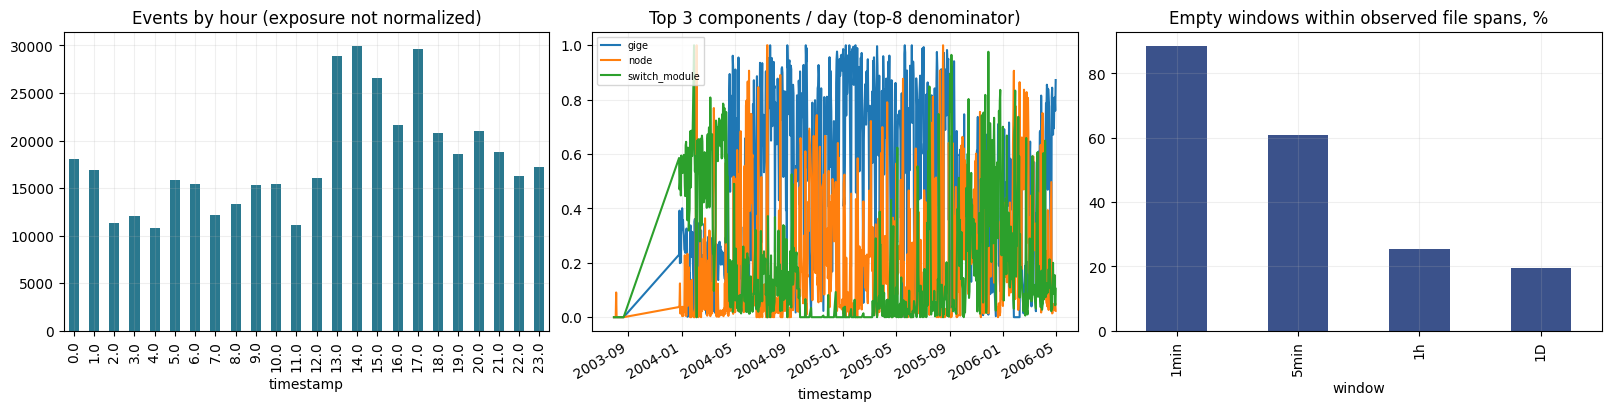

In [39]:
if bundle.labels.empty:
    display(Markdown("В архиве нет подтверждённых меток аномалий; качество детектора по этим данным оценить нельзя."))
else:
    show_table(t["labels_source"], 60)
    for table in ["label_units", "session_summary", "context_label", "label_comparison", "level_by_label", "anomaly_examples", "failure_context_episodes", "templates_context_exclusive"]:
        if table in t:
            display(Markdown("**" + table + "**"))
            show_table(t[table], 15)
plot_dynamics(bundle, result, OUT)

### 10. Временные окна

В длинном логе особенно заметно, как размер окна влияет на долю пустых интервалов. Сравниваю минуту, пять минут, час и сутки. События без читаемого времени остаются в текстовой статистике и пропускаются при подсчёте окон.

In [40]:
show_table(t["windows"])
assert int(df.physical_lines.sum()) == bundle.quality["physical_lines"]
assert int(df.parse_ok.sum()) + int((~df.parse_ok).sum()) == len(df)
assert len(bundle.raw_first) == min(100, bundle.quality["physical_lines"])
assert len(bundle.raw_random) == min(100, bundle.quality["physical_lines"])
print("Учёт исходных строк и размеры выборок проверены.")

,window,windows,empty,empty_pct,mean,median,p99,max
0,1min,1445785,1280228,88.549,0.300,0.0,3.00,1008
1,5min,289158,175542,60.708,1.499,0.0,13.00,1938
2,1h,24097,6159,25.559,17.989,6.0,226.04,4354
3,1D,1005,196,19.502,431.324,189.0,4554.72,16068


Учёт исходных строк и размеры выборок проверены.


### 11. Что получилось на HPC

В файле 433 490 строк и столько же событий. Есть 16 817 точных повторов и девять записей, у которых не удалось прочитать время. Корректные отметки охватывают период с 31 июля 2003 года по 30 апреля 2006 года по UTC.

В исходном порядке время пошло назад 227 832 раза. Для анализа последовательностей сначала нужно отсортировать события внутри каждого хоста или ресурса. Самая длинная пауза составляет 125,68 суток. По самому файлу её причину установить не удалось.

Из 1 161 шаблона десять самых частых покрывают 79,47% событий. Пустыми оказались 88,55% минутных окон. В самой активной минуте было 1 008 событий. Перед использованием `numeric_flag` нужно выяснить, что означает это поле. Для проверки качества детектора понадобятся метки.

In [41]:
del df, bundle, result, t
gc.collect()

28905

## Сравнение четырёх наборов

In [42]:
summary = pd.DataFrame(SUMMARIES).set_index("dataset")
show_table(summary, 4)
summary.to_csv(REPORT_DIR / "summary.csv", encoding="utf-8-sig")

,duplicate_physical_lines,physical_lines,physical_characters,lines_without_standard_header,blank_lines,invalid_utf8_lines,crlf_lines,missing_final_newline,continuation_lines,logical_events,timestamp_missing,start,end,unique_templates,top10_template_share_pct,mean_message_length,singleton_messages,files,sample_text_events,backwards_steps,duplicate_timestamps_within_files,missing_tag_separator
dataset,,,,,,,,,,,,,,,,,,,,,,
Hadoop,214689,394310,47809614,213414,877,0,391673,2,213414.0,180896,0,2015-10-17 15:37:56.547000,2015-10-19 18:08:58.030000,4586,58.360,165.814,51838,978,100000,13,62068,NaN
OpenStack,0,207820,61234262,0,0,0,0,0,NaN,207820,0,2017-05-14 19:39:01.445000,2017-05-17 12:02:35.320000,433,66.492,195.608,147426,3,100000,0,6585,NaN
Android,137801,1555005,188665469,64,0,0,1555005,0,NaN,1555005,0,2000-12-17 19:31:36.263000,2000-12-18 19:53:49.423000,71109,17.124,70.339,232692,1,100000,418,914092,64.0
HPC,16817,433490,32686525,0,0,0,433489,1,NaN,433490,9,2003-07-31 11:04:04+00:00,2006-04-30 11:28:24+00:00,1161,79.467,26.521,4222,1,100000,227832,158327,NaN


## Что брать в следующий этап

Таблица получена на полных архивах 8 ноября 2026 года.

| Датасет | Исходные строки | События | Шаблоны по регулярным выражениям | События без времени |
|---|---:|---:|---:|---:|
| Hadoop | 394 310 | 180 896 | 4 586 | 0 |
| OpenStack | 207 820 | 207 820 | 433 | 0 |
| Android | 1 555 005 | 1 555 005 | 71 109 | 0 |
| HPC | 433 490 | 433 490 | 1 161 | 9 |

Для первой модели с разметкой я бы начал с Hadoop. Там понятны границы заданий и известен сценарий каждого запуска. OpenStack ближе к теме облака, но всего четыре машины с известными сбоями. На нём стоит отдельно проверить, удаётся ли связать события одной машины и отделить обычные операции от сбоя. Android и HPC пока подходят для проверки парсера и методов без разметки.

Для первой версии признаков взял бы число событий и частоты шаблонов по окнам, уровни, длины сообщений и паузы. Словарь шаблонов для модели нужно строить на обучающей части. Затем можно сравнить регулярные выражения с Drain и подобрать размер окна для каждого набора.

До обучения стоит уточнить часовые пояса, год Android, значение `numeric_flag` в HPC и границы сбоев в OpenStack. Для длинных пауз полезно проверить, насколько полон сбор логов.

При использовании данных указывайте LogHub и статьи по соответствующим датасетам. Условия использования есть в описании коллекции. [LogHub](https://github.com/logpai/loghub) · [Архивы Zenodo](https://zenodo.org/records/3227177) · [Статья LogHub, ISSRE 2023](https://arxiv.org/abs/2008.06448)